# Competição e apresentação final — Grupo 10

**Disciplina:** Inteligência Artificial — **Professora:** Cristiane Neri Nobre | **Entrega:** 28/11/2026 | **Valor:** 5,00 pontos.

Este notebook consolida a entrega final da competição pelo **Grupo 10**:
- **Seção 1 — Samuel Lucas Rodrigues Vieira:** Reconstrução do vencedor da Etapa 3 e ajuste determinístico do pipeline final.
- **Seção 2 — Matheus de Almeida Moreira:** Diagnóstico de desempenho em validação interna fora da dobra, conflitos e erro residual.
- **Seção 3 — Arthur Soares Rolla:** Explicabilidade do modelo vencedor (SHAP interventional, amostra estratificada e importância por permutação fora da dobra).
- **Seção 4 — Carlos Eduardo de Melo Sabino:** Geração reprodutível e verificação do arquivo `submissao_10.csv`.
- **Seção 5 — Paulo Gabriel de Oliveira Leite:** Checklist independente do CSV, auditoria contra vazamento e ficha da entrega.

## Regras comuns às cinco tarefas

- Usar os CSVs oficiais em `data/`: `treino.csv`, `teste_sem_rotulo.csv` e `modelo_de_submissao.csv`.
- O alvo é `class`, com valores `normal` e `anomaly`; não remapear para cinco famílias de ataques.
- Não substituir, reembaralhar ou recriar a separação oficial de treino/teste. Validação interna é permitida **somente dentro do treino**.
- Ajustar imputação, codificação, normalização, balanceamento e redução apenas no treino de cada dobra.
- `id` identifica o teste e não é atributo preditivo. O teste não tem gabarito disponível à equipe.
- Investigar a associação de **cada atributo** com a classe antes de treinar modelos. Correlação alta não prova vazamento sozinha.
- Examinar também as colunas adicionadas, inclusive `score_ids_legado`, `tipo_alerta_soc` e `tempo_resposta_analista_min`; justificar decisões pela origem e disponibilidade da informação.
- Não reutilizar conclusões ou números da base antiga. Não procurar/reconstruir rótulos do teste público.
- Cada membro deve produzir código comentado, resultados e uma conclusão autoral em sua seção, além de revisar a integração.

## Seção 1 — Reconstrução e treino final (Samuel Lucas Rodrigues Vieira)

**Tarefa:** Reconstituir a configuração selecionada na etapa 3 e ajustar o pipeline completo apenas em todo o treino.csv. Documentar versões, sementes e dependências; garantir que a reprodução não dependa de objetos deixados em memória por outro notebook.

**Entregável:** Pipeline final treinado e procedimento reproduzível do início ao fim, sem fit ou fit_transform no teste.


### 1.1 Procedimento, ambiente e sementes

A seção é **autocontida**: não lê variáveis de outros notebooks nem de outras seções. O procedimento é sempre o mesmo, e cada execução de *Restart & Run All* o refaz do zero:

1. registrar versões, sementes e a impressão digital de `treino.csv`;
2. redefinir as transformações do protocolo comum (notebook 03, seção 1.1) e a configuração vencedora da etapa 3 (`CONFIG_VENCEDOR_ETAPA3`, seção 5.5), escrita aqui como literal;
3. **conferir** que a seleção interna da etapa 3, refeita sobre todo o treino, escolhe de novo os mesmos hiperparâmetros e o mesmo limiar;
4. ajustar o pipeline final em **todo** o `treino.csv`, aplicando o filtro de conflitos apenas a ele;
5. conferir se o ajuste é determinístico e salvar o pipeline e a configuração para a seção 4.

O teste oficial **não é lido** nesta seção. Só o cabeçalho de `teste_sem_rotulo.csv` é usado, para conferir o esquema de colunas, e nenhum `fit`/`fit_transform` recebe dados do teste. Quem aplica `predict` ao teste é a seção 4.

`sha256` é calculado sobre o conteúdo com fim de linha LF. O Git deste repositório usa `text=auto`, então o checkout no Windows grava o CSV com CRLF, e o hash dos bytes brutos mudaria de máquina para máquina sem que nenhum dado tenha mudado.

In [1]:
# Membro 1 — 1.1 Ambiente, versões, sementes e impressão digital dos dados
from pathlib import Path
from itertools import product
import hashlib
import json
import platform
import time

import joblib
import numpy as np
import pandas as pd
import sklearn
import imblearn
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEMENTE = 42                      # mesma semente das etapas 2 e 3: dobras, seleção interna e floresta
N_DOBRAS = 5

project_root = Path.cwd().resolve()
if not (project_root / "data" / "treino.csv").exists():
    project_root = project_root.parent
if not (project_root / "data" / "treino.csv").exists():
    raise FileNotFoundError("Execute na raiz do projeto ou em notebooks/.")
DIR_DADOS = project_root / "data"
DIR_MODELOS = project_root / "models"

COL_ROTULO = "class"
COL_ID = "id"
CLASSES = ["normal", "anomaly"]   # 0 = normal, 1 = anomaly (classe positiva)
COLS_CATEGORICAS = ["protocol_type", "service", "flag"]
SINAIS_OPERACIONAIS = ["score_ids_legado", "tipo_alerta_soc", "tempo_resposta_analista_min"]
COLS_DERIVADAS = ("src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod")
LIMITES_DOMINIO = {               # limites da documentação do KDD (conhecimento prévio, não aprendidos)
    **{c: (0, 1) for c in ["serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
                           "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
                           "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
                           "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
                           "dst_host_serror_rate", "dst_host_srv_serror_rate",
                           "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]},
    "same_srv_pct": (0, 100),
    "count": (0, 511), "srv_count": (0, 511),
    "dst_host_count": (0, 255), "dst_host_srv_count": (0, 255),
    "duration": (0, np.inf), "src_bytes": (0, np.inf), "dst_bytes": (0, np.inf),
    "total_bytes": (0, np.inf), "src_bytes_kb": (0, np.inf), "dst_bytes_kb": (0, np.inf),
}


def sha256_texto(caminho):
    # Hash do CSV com fim de linha normalizado para LF (independe do checkout CRLF/LF do Git).
    return hashlib.sha256(Path(caminho).read_bytes().replace(b"\r\n", b"\n")).hexdigest()


VERSOES = {"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
           "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
           "joblib": joblib.__version__}
# Versões registradas pela etapa 3 ao selecionar o vencedor (notebook 03, seção 5.5).
VERSOES_ETAPA3 = {"Python": "3.13.14", "numpy": "2.5.2", "pandas": "3.0.5",
                  "scikit-learn": "1.9.0", "imbalanced-learn": "0.14.2"}
HASH_TREINO = sha256_texto(DIR_DADOS / "treino.csv")

display(pd.DataFrame({"esta execução": VERSOES, "etapa 3": VERSOES_ETAPA3}).fillna("—"))
print("Sistema:", platform.platform())
print("sha256(treino.csv, LF):", HASH_TREINO)


,esta execução,etapa 3
Python,3.13.14,3.13.14
numpy,2.5.2,2.5.2
pandas,3.0.5,3.0.5
scikit-learn,1.9.0,1.9.0
imbalanced-learn,0.14.2,0.14.2
joblib,1.5.3,—


Sistema: macOS-27.2.1-arm64-arm-64bit-Mach-O
sha256(treino.csv, LF): 9713c75938ef1e9e513975f256d65a80c4b05df533d35336c67387020bf76b7f


### 1.2 Transformações do protocolo comum

As definições abaixo são cópias das usadas na etapa 3 (notebook 03, seção 1.1), mantidas apenas no que o vencedor usa: o pré-processamento P2 não aplica escala e dispensa a reamostragem. Tudo o que é aprendido dos dados fica em um `fit`: constantes, medianas, categorias frequentes do One-Hot e grupos conflitantes. Nesta seção, o `fit` recebe somente o treino.

| Etapa | Aprende dos dados? | Configuração do vencedor |
|---|---|---|
| `NormalizarCategorias` | Não | strip + minúsculas em `protocol_type`, `service`, `flag` |
| `TratarForaDominio` | Não | valores fora dos limites da documentação → ausente |
| `RemoverRedundantes` | Sim (constantes) | remove as 5 derivadas determinísticas e as constantes do treino |
| `SimpleImputer` numérico | Sim (mediana) | mediana, sem indicador |
| `SimpleImputer` categórico | Não | categoria `__ausente__` |
| `OneHotEncoder` | Sim (categorias) | categorias com < 100 registros agrupadas em `infrequent_sklearn`; desconhecidas → grupo raro |
| `filtrar_linhas_treino` | Sim (grupos) | remove do treino os registros idênticos com classes divergentes |

In [2]:
# Membro 1 — 1.2 Transformações (cópia fiel do notebook 03, seção 1.1, restrita ao que o vencedor usa)
def carregar_treino(incluir_operacionais: bool = False):
    # Lê treino.csv sem alterá-lo. Retorna (X, y) com y = 1 para anomaly.
    df = pd.read_csv(DIR_DADOS / "treino.csv")
    assert set(df[COL_ROTULO]) == set(CLASSES) and df[COL_ROTULO].notna().all()
    assert COL_ID not in df.columns, "id não é atributo preditivo."
    descartar = [COL_ROTULO] + ([] if incluir_operacionais else SINAIS_OPERACIONAIS)
    return df.drop(columns=descartar), (df[COL_ROTULO] == "anomaly").astype(int).rename(COL_ROTULO)


class NormalizarCategorias(BaseEstimator, TransformerMixin):
    # strip + minúsculas nos categóricos ('TCP ' -> 'tcp'). Sem estado; NaN continua NaN.
    def __init__(self, colunas=tuple(COLS_CATEGORICAS), ativo=True):
        self.colunas = colunas
        self.ativo = ativo

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.colunas:
            if c in X:
                serie = X[c].astype(object)
                X[c] = serie.str.strip().str.lower() if self.ativo else serie
        return X


class TratarForaDominio(BaseEstimator, TransformerMixin):
    # 'manter' | 'ausente' (vira NaN) | 'recorte' (clip). Limites da documentação, sem estado.
    def __init__(self, modo="manter"):
        self.modo = modo

    def fit(self, X, y=None):
        assert self.modo in {"manter", "ausente", "recorte"}
        return self

    def transform(self, X):
        if self.modo == "manter":
            return X
        X = X.copy()
        for c, (lo, hi) in LIMITES_DOMINIO.items():
            if c in X:
                X[c] = (X[c].astype(float).mask((X[c] < lo) | (X[c] > hi)) if self.modo == "ausente"
                        else X[c].clip(lower=lo, upper=hi))
        return X


class RemoverRedundantes(BaseEstimator, TransformerMixin):
    # Remove derivadas determinísticas (lista fixa) e constantes detectadas no conjunto do fit.
    def __init__(self, ativo=True):
        self.ativo = ativo

    def fit(self, X, y=None):
        constantes = [c for c in X.columns if X[c].nunique(dropna=True) <= 1] if self.ativo else []
        self.remover_ = sorted(set(COLS_DERIVADAS).intersection(X.columns) | set(constantes)) if self.ativo else []
        return self

    def transform(self, X):
        return X.drop(columns=self.remover_)


def _eh_categorica(X):
    return [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]


def _eh_numerica(X):
    return [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]


def montar_preprocessamento(normalizar_categorias=True, fora_dominio="manter", remover_redundantes=False,
                            imputacao_num="mediana", imputacao_cat="constante", codificacao="onehot",
                            escala=None):
    # Mesma assinatura da etapa 3. O vencedor usa escala=None (florestas não dependem de escala).
    if escala is not None:
        raise ValueError("Esta seção reconstrói apenas o vencedor, que não usa escala.")
    imp_num = SimpleImputer(strategy="median", add_indicator=(imputacao_num == "mediana+indicador"))
    numerico = Pipeline([("imp", imp_num), ("escala", "passthrough")])
    imp_cat = (SimpleImputer(strategy="constant", fill_value="__ausente__") if imputacao_cat == "constante"
               else SimpleImputer(strategy="most_frequent"))
    ohe = (OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False)
           if codificacao == "onehot_raras" else OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    colunas = ColumnTransformer([
        ("num", numerico, _eh_numerica),
        ("cat", Pipeline([("imp", imp_cat), ("ohe", ohe)]), _eh_categorica),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ("categorias", NormalizarCategorias(ativo=normalizar_categorias)),
        ("dominio", TratarForaDominio(modo=fora_dominio)),
        ("redundantes", RemoverRedundantes(ativo=remover_redundantes)),
        ("imputacao_codificacao", colunas),
    ])


def chave_registro(X):
    # Identificador de registros com atributos idênticos (categorias normalizadas, NaN como valor).
    Xn = NormalizarCategorias().transform(X)
    return pd.Series(pd.factorize(pd.util.hash_pandas_object(Xn, index=False))[0], index=X.index)


def filtrar_linhas_treino(X, y, estrategia="todas"):
    # 'todas' | 'sem_conflitos': remove grupos idênticos com classes divergentes do conjunto recebido.
    if estrategia == "todas":
        return X, y
    if estrategia != "sem_conflitos":
        raise ValueError(estrategia)
    chave = chave_registro(X)
    manter = ~chave.map(y.groupby(chave).nunique()).gt(1)
    return X[manter], y[manter]


X_treino, y_treino = carregar_treino()
grupos_treino = chave_registro(X_treino)
print(f"Treino: {X_treino.shape[0]:,} linhas x {X_treino.shape[1]} atributos; "
      f"{grupos_treino.nunique():,} registros distintos; anomaly = {y_treino.mean():.2%}")


Treino: 69,833 linhas x 46 atributos; 56,766 registros distintos; anomaly = 5.84%


### 1.3 Configuração vencedora da etapa 3

O vencedor foi escolhido no notebook 03 (seção 5.3) pela regra determinística da seção 5.1: **Random Forest com seleção aninhada de hiperparâmetros e limiar de decisão interno, sobre o pré-processamento P2** (F1-macro de validação 0,8818 ± 0,0007). Os valores abaixo foram copiados de `CONFIG_VENCEDOR_ETAPA3`. Os hiperparâmetros e o limiar não são números escolhidos à mão: saem de um procedimento fixo, a seleção interna em 3 dobras por grupos sobre todo o treino. Por isso, a seção 1.4 refaz esse procedimento e exige que ele leve aos mesmos valores.

`PipelineFinalIDS` junta, em um único estimador, as três partes que precisam andar juntas:
- o **filtro de conflitos**, que remove linhas e por isso não cabe em um `Pipeline` do scikit-learn. Ele age só no `fit`;
- o **pipeline** de pré-processamento + floresta;
- o **limiar** de decisão 0,37 aplicado em `predict`.

Assim, `fit` recebe apenas o treino e `predict` apenas transforma. Não há como reajustar algo no teste por engano.

In [3]:
# Membro 1 — 1.3 Configuração vencedora (literal de CONFIG_VENCEDOR_ETAPA3) e estimador final
CONFIG_FINAL = {
    "candidato": "RF aninhada + limiar · P2",
    "classe_modelo": "RandomForestClassifier",
    "parametros_modelo": dict(n_estimators=300, criterion="gini", max_depth=None, min_samples_split=2,
                              min_samples_leaf=1, max_features=0.3, bootstrap=True,
                              class_weight={0: 1.0, 1: 4.0}, n_jobs=-1, random_state=SEMENTE),
    "limiar_decisao": 0.37,
    "combinacao": "P2 P1 + raras agrupadas",
    "pre_processamento": dict(normalizar_categorias=True, fora_dominio="ausente", remover_redundantes=True,
                              imputacao_num="mediana", imputacao_cat="constante", codificacao="onehot_raras"),
    "escala": None,
    "linhas_treino": "sem_conflitos",
    "balanceamento": None,
    "colunas_fora_dos_preditores": [COL_ID, COL_ROTULO, *SINAIS_OPERACIONAIS],
    "dados": {"arquivo": "data/treino.csv",
              "sha256_lf": "9713c75938ef1e9e513975f256d65a80c4b05df533d35336c67387020bf76b7f",
              "linhas": 69833, "atributos": 46},
    "sementes": {"dobras": SEMENTE, "selecao_interna": SEMENTE, "modelo": SEMENTE},
    "validacao_etapa3": {"assinatura_dobras": "8a814c72d149c698", "f1_macro_media": 0.8818,
                         "f1_macro_dp": 0.0007, "f1_macro_interno_limiar": 0.8806},
}

# Procedimento que gerou os hiperparâmetros e o limiar (notebook 03, seções 2.1 e 2.3).
RF_BASE = RandomForestClassifier(n_estimators=300, criterion="gini", max_depth=None, min_samples_leaf=1,
                                 max_features="sqrt", bootstrap=True, class_weight=None,
                                 n_jobs=-1, random_state=SEMENTE)
GRADE_RF = [dict(max_features=m, min_samples_leaf=f, class_weight=w)
            for m, f, w in product(["sqrt", 0.3], [1, 5],
                                   [None, {0: 1.0, 1: 2.0}, {0: 1.0, 1: 4.0}, "balanced_subsample"])]
LIMIARES_BUSCA = np.round(np.linspace(0.20, 0.70, 51), 2)

# Os dados atuais devem ser exatamente os usados na etapa 3.
assert HASH_TREINO == CONFIG_FINAL["dados"]["sha256_lf"], "treino.csv difere do usado na etapa 3"
assert X_treino.shape == (CONFIG_FINAL["dados"]["linhas"], CONFIG_FINAL["dados"]["atributos"])
assert not set(CONFIG_FINAL["colunas_fora_dos_preditores"]).intersection(X_treino.columns)


class PipelineFinalIDS(BaseEstimator, ClassifierMixin):
    # Filtro de conflitos (só no fit) + pré-processamento + floresta + limiar de decisão (no predict).

    def __init__(self, config):
        self.config = config

    def _montar(self):
        cfg = self.config
        assert cfg["balanceamento"] is None and cfg["escala"] is None
        modelo = RandomForestClassifier(**cfg["parametros_modelo"])
        prep = montar_preprocessamento(**cfg["pre_processamento"], escala=cfg["escala"])
        return Pipeline(prep.steps + [("modelo", modelo)])

    def fit(self, X, y):
        X_fit, y_fit = filtrar_linhas_treino(X, y, self.config["linhas_treino"])
        self.n_linhas_recebidas_ = len(X)
        self.n_linhas_ajuste_ = len(X_fit)
        self.colunas_entrada_ = list(X.columns)
        self.pipeline_ = self._montar().fit(X_fit, y_fit)          # ajuste paralelo (n_jobs=-1)
        # Inferência sequencial: com n_jobs=-1 a floresta soma as probabilidades das árvores em threads, em
        # ordem variável, gerando diferenças de arredondamento (~1e-16) que podem inverter casos exatamente
        # sobre o limiar (ex.: 111/300 = 0,37). Com n_jobs=1 a soma tem ordem fixa e a previsão é reproduzível.
        self.pipeline_.named_steps["modelo"].set_params(n_jobs=1)
        self.classes_ = self.pipeline_.classes_
        return self

    def predict_proba(self, X):
        assert list(X.columns) == self.colunas_entrada_, "colunas diferentes das usadas no ajuste"
        return self.pipeline_.predict_proba(X)          # só transform + predict; nada é reajustado

    def predict(self, X):
        # 1 = anomaly quando P(anomaly) >= limiar registrado na etapa 3.
        return (self.predict_proba(X)[:, 1] >= self.config["limiar_decisao"]).astype(int)

    def predict_rotulos(self, X):
        return pd.Series(np.asarray(CLASSES, dtype=object)[self.predict(X)], index=X.index, name="class_prevista")


print(json.dumps(CONFIG_FINAL, indent=2, ensure_ascii=False, default=str))


{
  "candidato": "RF aninhada + limiar · P2",
  "classe_modelo": "RandomForestClassifier",
  "parametros_modelo": {
    "n_estimators": 300,
    "criterion": "gini",
    "max_depth": null,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": 0.3,
    "bootstrap": true,
    "class_weight": {
      "0": 1.0,
      "1": 4.0
    },
    "n_jobs": -1,
    "random_state": 42
  },
  "limiar_decisao": 0.37,
  "combinacao": "P2 P1 + raras agrupadas",
  "pre_processamento": {
    "normalizar_categorias": true,
    "fora_dominio": "ausente",
    "remover_redundantes": true,
    "imputacao_num": "mediana",
    "imputacao_cat": "constante",
    "codificacao": "onehot_raras"
  },
  "escala": null,
  "linhas_treino": "sem_conflitos",
  "balanceamento": null,
  "colunas_fora_dos_preditores": [
    "id",
    "class",
    "score_ids_legado",
    "tipo_alerta_soc",
    "tempo_resposta_analista_min"
  ],
  "dados": {
    "arquivo": "data/treino.csv",
    "sha256_lf": "9713c75938ef1e9e

### 1.4 Reconstituição do procedimento de seleção

Copiar os números não basta para garantir que eles se reproduzem. Por isso, refazemos sobre todo o treino o procedimento da etapa 3 que os produziu:

1. **Dobras externas:** `StratifiedGroupKFold(5, shuffle=True, random_state=42)` sobre os grupos de registros idênticos. A partição precisa ter a assinatura `8a814c72d149c698` registrada nas etapas 2 e 3.
2. **Seleção interna:** em 3 dobras internas por grupos (semente 42), com o filtro de conflitos e o pré-processamento reajustados no treino de cada dobra interna, avaliamos a grade de 16 florestas pelo F1-macro com limiar 0,5. Em seguida, escolhemos o limiar de maior F1-macro entre 0,20 e 0,70 sobre as probabilidades fora da dobra do ponto escolhido.

Esta etapa só confere: **nenhum valor de `CONFIG_FINAL` é trocado pelo resultado**. São dois critérios:
- **Hiperparâmetros (exigência estrita):** o ponto escolhido da grade precisa ser `max_features=0.3`, `min_samples_leaf=1`, `class_weight={0: 1, 1: 4}`. Se não for, a execução para com erro.
- **Limiar (exigência de quase empate):** o limiar é escolhido em uma grade de passo 0,01 sobre uma curva de F1 quase plana, então pequenas diferenças numéricas entre ambientes (versões de Python e scikit-learn) podem mover o argmax para um vizinho. Por isso, exigimos que o F1-macro interno do limiar registrado (0,37) fique a menos de 0,001 do melhor limiar deste ambiente. A tabela mostra os dois valores. O limiar usado continua sendo o da etapa 3, porque mudá-lo seria uma nova seleção.

A conferência treina 48 florestas (cerca de 7 minutos); para pular, use `CONFERIR_SELECAO = False`.

In [4]:
# Membro 1 — 1.4 Conferência: dobras da etapa 3 e seleção interna refeita sobre todo o treino
CONFERIR_SELECAO = True


def metricas_f1_macro(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=[0, 1], zero_division=0)


def ajustar_limiar_f1_macro(y_true, prob_pos, limiares=LIMIARES_BUSCA):
    # Igual à etapa 3: maior F1-macro; em empate exato, o mais próximo de 0,5 e depois o menor.
    melhor_limiar, melhor_f1 = 0.5, -1.0
    for t in limiares:
        f1 = metricas_f1_macro(y_true, (prob_pos >= t).astype(int))
        if f1 > melhor_f1 + 1e-12 or (abs(f1 - melhor_f1) <= 1e-12 and
                                       (abs(float(t) - 0.5), float(t)) < (abs(melhor_limiar - 0.5), melhor_limiar)):
            melhor_limiar, melhor_f1 = float(t), float(f1)
    return melhor_limiar, melhor_f1


def selecao_interna(X, y, grupos, config):
    # Reproduz escolher_parametros(..., retornar_limiar=True) do notebook 03 (seção 2.3).
    internas = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
    notas = np.zeros((3, len(GRADE_RF)))
    prob_oof = np.zeros((len(GRADE_RF), len(X)))
    for k, (a, b) in enumerate(internas.split(X, y, grupos)):
        X_tr, y_tr = filtrar_linhas_treino(X.iloc[a], y.iloc[a], config["linhas_treino"])
        prep = montar_preprocessamento(**config["pre_processamento"], escala=config["escala"]).fit(X_tr, y_tr)
        Z_tr, Z_va = prep.transform(X_tr), prep.transform(X.iloc[b])      # validação interna intacta
        for j, p in enumerate(GRADE_RF):
            prob = clone(RF_BASE).set_params(**p).fit(Z_tr, y_tr).predict_proba(Z_va)
            prob_oof[j, b] = prob[:, 1]
            notas[k, j] = metricas_f1_macro(y.iloc[b], np.argmax(prob, axis=1))
    media = notas.mean(axis=0)
    melhor = int(np.argmax(media))
    limiar, f1_limiar = ajustar_limiar_f1_macro(y.to_numpy(), prob_oof[melhor])
    return GRADE_RF[melhor], limiar, f1_limiar, media, prob_oof[melhor]


# 1) Mesmas dobras externas das etapas 2 e 3.
dobras = list(StratifiedGroupKFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE)
              .split(X_treino, y_treino, grupos_treino))
dobra_de_cada_linha = np.empty(len(X_treino), dtype=int)
for i, (_, iva) in enumerate(dobras, start=1):
    dobra_de_cada_linha[iva] = i
ASSINATURA_DOBRAS = hashlib.sha256(dobra_de_cada_linha.tobytes()).hexdigest()[:16]
assert ASSINATURA_DOBRAS == CONFIG_FINAL["validacao_etapa3"]["assinatura_dobras"], ASSINATURA_DOBRAS
print("Assinatura das dobras:", ASSINATURA_DOBRAS, "(igual à da etapa 3)")

# 2) Seleção interna sobre todo o treino.
if CONFERIR_SELECAO:
    inicio = time.perf_counter()
    melhor_ref, limiar_ref, f1_limiar_ref, media_grade, prob_oof_ref = selecao_interna(
        X_treino, y_treino, grupos_treino, CONFIG_FINAL)
    print(f"Seleção interna refeita em {time.perf_counter() - inicio:.0f} s.")
    rot = lambda v: "None" if v is None else str(v)
    grade_tab = pd.DataFrame([{k: rot(v) for k, v in p.items()} | {"f1_macro_interno": m}
                              for p, m in zip(GRADE_RF, media_grade)])
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(grade_tab.pivot_table(index=["class_weight", "max_features"], columns="min_samples_leaf",
                                      values="f1_macro_interno"))
    esperado = {k: CONFIG_FINAL["parametros_modelo"][k] for k in melhor_ref}
    limiar_cfg = CONFIG_FINAL["limiar_decisao"]
    f1_limiar_cfg = metricas_f1_macro(y_treino, (prob_oof_ref >= limiar_cfg).astype(int))
    display(pd.DataFrame({
        "registrado na etapa 3": {**{k: rot(v) for k, v in esperado.items()}, "limiar_decisao": limiar_cfg,
                                  "F1-macro interno no limiar registrado": f"{f1_limiar_cfg:.4f}"},
        "refeito neste ambiente": {**{k: rot(v) for k, v in melhor_ref.items()}, "limiar_decisao": limiar_ref,
                                   "F1-macro interno no limiar registrado": f"{f1_limiar_ref:.4f} (no limiar {limiar_ref:.2f})"},
    }))
    curva = pd.Series({t: metricas_f1_macro(y_treino, (prob_oof_ref >= t).astype(int))
                       for t in LIMIARES_BUSCA if 0.30 <= t <= 0.45}, name="F1-macro interno")
    print("Curva de F1-macro interno em torno dos limiares (probabilidades fora da dobra do ponto escolhido):")
    display(curva.to_frame().T.round(4))
    print(f"Etapa 3 registrou F1-macro interno {CONFIG_FINAL['validacao_etapa3']['f1_macro_interno_limiar']:.4f} "
          f"no limiar {limiar_cfg:.2f}; diferença entre o limiar registrado e o melhor deste ambiente: "
          f"{f1_limiar_ref - f1_limiar_cfg:.4f}")
    assert melhor_ref == esperado, "os hiperparâmetros refeitos divergem da etapa 3"
    assert f1_limiar_ref - f1_limiar_cfg < 1e-3, "o limiar registrado deixou de ser um quase empate"
    print("Conferência aprovada: hiperparâmetros idênticos aos da etapa 3; limiar registrado "
          f"{'idêntico' if limiar_ref == limiar_cfg else 'em quase empate com o melhor deste ambiente'}.")
else:
    print("Conferência da seleção interna pulada (CONFERIR_SELECAO = False).")


Assinatura das dobras: 8a814c72d149c698 (igual à da etapa 3)


Seleção interna refeita em 50 s.


min_samples_leaf                     1      5
class_weight       max_features              
None               0.3          0.8762 0.8685
                   sqrt         0.8737 0.8625
balanced_subsample 0.3          0.8724 0.8736
                   sqrt         0.8708 0.8715
{0: 1.0, 1: 2.0}   0.3          0.8785 0.8744
                   sqrt         0.8770 0.8687
{0: 1.0, 1: 4.0}   0.3          0.8787 0.8770
                   sqrt         0.8766 0.8725

,registrado na etapa 3,refeito neste ambiente
max_features,0.3,0.3
min_samples_leaf,1,1
class_weight,"{0: 1.0, 1: 4.0}","{0: 1.0, 1: 4.0}"
limiar_decisao,0.37,0.37
F1-macro interno no limiar registrado,0.8806,0.8806 (no limiar 0.37)


Curva de F1-macro interno em torno dos limiares (probabilidades fora da dobra do ponto escolhido):


,0.30,0.31,0.32,0.33,0.34,0.35,0.36,0.37,0.38,0.39,0.40,0.41,0.42,0.43,0.44,0.45
F1-macro interno,0.8788,0.8792,0.8795,0.8794,0.8796,0.8799,0.8801,0.8806,0.8802,0.8803,0.8803,0.8801,0.8799,0.8797,0.8798,0.8796


Etapa 3 registrou F1-macro interno 0.8806 no limiar 0.37; diferença entre o limiar registrado e o melhor deste ambiente: 0.0000
Conferência aprovada: hiperparâmetros idênticos aos da etapa 3; limiar registrado idêntico.


### 1.5 Treino final em todo o `treino.csv`

O estimador final é ajustado **uma única vez** sobre as 69.833 linhas do treino, sem separar validação: a validação interna já cumpriu seu papel nas etapas 2 e 3, e o modelo submetido deve aproveitar todos os dados rotulados. Como em cada dobra, o filtro de conflitos remove do conjunto de ajuste os grupos de registros idênticos com classes opostas. Medianas, constantes e categorias do One-Hot são aprendidas com o treino filtrado.

Para conferir o determinismo, ajustamos o estimador uma segunda vez, a partir de um objeto novo. Exigimos que as 300 árvores sejam idênticas (estrutura, atributos, limiares e folhas) e que as probabilidades **sobre o próprio treino** sejam iguais bit a bit. O teste não é usado nem nessa comparação. O ajuste roda em paralelo (`n_jobs=-1`), mas a inferência usa `n_jobs=1`. Com várias threads, a floresta soma as probabilidades das árvores em ordem variável, o que gera diferenças de arredondamento (~1e-16). Essas diferenças podem inverter a decisão de um registro cuja probabilidade cai exatamente sobre o limiar (por exemplo, 111/300 = 0,37). Com a soma em ordem fixa, uma nova execução gera exatamente o mesmo arquivo de submissão, como a seção 4 confirma pelo hash do arquivo.

In [5]:
# Membro 1 — 1.5 Ajuste final em todo o treino (o teste não participa de nenhum fit)
inicio = time.perf_counter()
pipeline_final = PipelineFinalIDS(CONFIG_FINAL).fit(X_treino, y_treino)
segundos_ajuste = time.perf_counter() - inicio

pipe = pipeline_final.pipeline_
rf = pipe.named_steps["modelo"]
ct = pipe.named_steps["imputacao_codificacao"]
ohe = ct.named_transformers_["cat"].named_steps["ohe"]
cols_cat = next(cols for nome, _, cols in ct.transformers_ if nome == "cat")   # colunas resolvidas no fit
y_fit = filtrar_linhas_treino(X_treino, y_treino, CONFIG_FINAL["linhas_treino"])[1]
nomes_saida = ct.get_feature_names_out()

resumo_ajuste = {
    "linhas recebidas (treino.csv)": f"{pipeline_final.n_linhas_recebidas_:,}",
    "linhas removidas pelo filtro de conflitos": f"{pipeline_final.n_linhas_recebidas_ - pipeline_final.n_linhas_ajuste_:,}",
    "linhas usadas no ajuste": f"{pipeline_final.n_linhas_ajuste_:,}",
    "anomaly antes / depois do filtro": f"{y_treino.mean():.2%} / {y_fit.mean():.2%}",
    "atributos de entrada": len(pipeline_final.colunas_entrada_),
    "colunas removidas (derivadas + constantes)": ", ".join(pipe.named_steps["redundantes"].remover_),
    "colunas após imputação e One-Hot": len(nomes_saida),
    "categorias distintas no treino (normalizadas)": ", ".join(f"{c}: {len(cat)}" for c, cat in
                                                  zip(cols_cat, ohe.categories_)),
    "categorias agrupadas como raras": ", ".join(f"{c}: {0 if inf is None else len(inf)}" for c, inf in
                                                 zip(cols_cat, ohe.infrequent_categories_)),
    "árvores / profundidade média / folhas médias": (f"{len(rf.estimators_)} / "
                                                     f"{np.mean([a.get_depth() for a in rf.estimators_]):.1f} / "
                                                     f"{np.mean([a.get_n_leaves() for a in rf.estimators_]):.0f}"),
    "limiar de decisão": CONFIG_FINAL["limiar_decisao"],
    "tempo de ajuste (s)": f"{segundos_ajuste:.1f}",
}
with pd.option_context("display.max_colwidth", 150):
    display(pd.Series(resumo_ajuste, name="pipeline final").to_frame())

# Determinismo: um segundo ajuste independente deve gerar as mesmas 300 árvores e as mesmas probabilidades.
segundo = PipelineFinalIDS(CONFIG_FINAL).fit(X_treino, y_treino)
arvores_iguais = all(
    all(np.array_equal(getattr(a.tree_, campo), getattr(b.tree_, campo))
        for campo in ("children_left", "children_right", "feature", "threshold", "value"))
    for a, b in zip(rf.estimators_, segundo.pipeline_.named_steps["modelo"].estimators_))
assert arvores_iguais, "o ajuste não é determinístico"
prob_1 = pipeline_final.predict_proba(X_treino)
assert np.array_equal(prob_1, segundo.predict_proba(X_treino)), "a inferência não é determinística"
assert np.array_equal(prob_1, pipeline_final.predict_proba(X_treino))
IMPRESSAO_MODELO = hashlib.sha256(np.ascontiguousarray(prob_1).tobytes()).hexdigest()[:16]
print("Dois ajustes independentes geram as mesmas 300 árvores (estrutura, limiares e folhas) "
      "e probabilidades idênticas bit a bit no treino.")
print("Impressão digital do modelo (sha256 das probabilidades no treino):", IMPRESSAO_MODELO)


,pipeline final
linhas recebidas (treino.csv),"69,833"
linhas removidas pelo filtro de conflitos,"3,730"
linhas usadas no ajuste,"66,103"
anomaly antes / depois do filtro,5.84% / 3.30%
atributos de entrada,46
colunas removidas (derivadas + constantes),"dst_bytes_kb, num_outbound_cmds, protocolo_cod, same_srv_pct, src_bytes_kb, total_bytes"
colunas após imputação e One-Hot,67
categorias distintas no treino (normalizadas),"protocol_type: 3, service: 66, flag: 12"
categorias agrupadas como raras,"protocol_type: 0, service: 49, flag: 4"
árvores / profundidade média / folhas médias,300 / 25.6 / 329


Dois ajustes independentes geram as mesmas 300 árvores (estrutura, limiares e folhas) e probabilidades idênticas bit a bit no treino.
Impressão digital do modelo (sha256 das probabilidades no treino): 676b7dadfe54344b


### 1.6 Contrato com o teste e artefatos para a seção 4

Antes de entregar o pipeline, conferimos o esquema de `teste_sem_rotulo.csv` lendo **apenas o cabeçalho** (`nrows=0`, sem nenhum valor do teste). Depois de retirar `id` e os sinais operacionais, as colunas precisam ser as mesmas do treino, na mesma ordem. Em seguida, salvamos em `models/`:

- `pipeline_final.joblib`: estimador ajustado. O `.gitignore` exclui esse arquivo do repositório, porque ele é recriado por esta seção;
- `config_final.json`: configuração, versões, `sha256` dos dados e impressão digital do modelo.

A seção 4 usa `pipeline_final.predict_rotulos(X_teste)`, que apenas transforma e prevê. Para carregar o `.joblib` em outra sessão, as classes desta seção precisam estar definidas, porque o `pickle` guarda referências a elas. Por isso, o caminho reproduzível é executar esta seção.

In [6]:
# Membro 1 — 1.6 Esquema do teste (só o cabeçalho) e artefatos salvos
def carregar_teste(incluir_operacionais: bool = False):
    # Para o Membro 4: lê o teste preservando ordem e IDs. Nenhuma estatística é calculada com ele.
    df = pd.read_csv(DIR_DADOS / "teste_sem_rotulo.csv")
    descartar = [COL_ID] + ([] if incluir_operacionais else SINAIS_OPERACIONAIS)
    return df[COL_ID].copy(), df.drop(columns=descartar)


cabecalho_teste = pd.read_csv(DIR_DADOS / "teste_sem_rotulo.csv", nrows=0).columns.tolist()
colunas_teste = [c for c in cabecalho_teste if c not in [COL_ID, *SINAIS_OPERACIONAIS]]
assert COL_ID in cabecalho_teste and COL_ROTULO not in cabecalho_teste
assert colunas_teste == pipeline_final.colunas_entrada_, "esquema do teste difere do treino"
print(f"Esquema do teste compatível: {len(cabecalho_teste)} colunas no arquivo -> "
      f"{len(colunas_teste)} preditores na mesma ordem do treino (sem id e sem sinais operacionais).")

DIR_MODELOS.mkdir(exist_ok=True)
caminho_pipeline = DIR_MODELOS / "pipeline_final.joblib"
joblib.dump(pipeline_final, caminho_pipeline, compress=3)
registro = {
    **CONFIG_FINAL,
    "procedimento": "PipelineFinalIDS(CONFIG_FINAL).fit(*carregar_treino()) no notebook 04, seção do Membro 1",
    "versoes_execucao": VERSOES,
    "sha256_treino_lf": HASH_TREINO,
    "assinatura_dobras_conferida": ASSINATURA_DOBRAS,
    "selecao_interna_conferida": CONFERIR_SELECAO,
    "linhas_ajuste": pipeline_final.n_linhas_ajuste_,
    "impressao_modelo": IMPRESSAO_MODELO,
}
(DIR_MODELOS / "config_final.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False, default=str),
                                               encoding="utf-8")
print(f"Salvos: {caminho_pipeline.relative_to(project_root)} "
      f"({caminho_pipeline.stat().st_size / 2**20:.1f} MiB) e models/config_final.json")


Esquema do teste compatível: 50 colunas no arquivo -> 46 preditores na mesma ordem do treino (sem id e sem sinais operacionais).
Salvos: models/pipeline_final.joblib (3.8 MiB) e models/config_final.json


### Resultados e justificativa — Seção 1

**Configuração reconstituída.** O pipeline final é o vencedor da etapa 3 (notebook 03, seções 5.3 e 5.5): `RandomForestClassifier(n_estimators=300, max_features=0.3, min_samples_leaf=1, max_depth=None, class_weight={0: 1.0, 1: 4.0}, bootstrap=True, random_state=42)` sobre o pré-processamento P2. P2 normaliza as categorias, transforma valores fora do domínio em ausentes, remove as 5 derivadas e a constante `num_outbound_cmds`, imputa a mediana e a categoria `__ausente__` e aplica One-Hot com categorias raras (< 100) agrupadas. A versão final usa o filtro de conflitos apenas no treino, não usa reamostragem nem escala e aplica o limiar de decisão **0,37**. Os sinais operacionais, `id` e `class` continuam fora dos preditores. A configuração está como literal em `CONFIG_FINAL`, e nenhuma escolha foi refeita nesta etapa.

**Reprodutibilidade conferida (1.1 e 1.4).**
- **Dados:** `treino.csv` tem `sha256 = 9713c759…76b7f` com fim de linha LF, o mesmo valor registrado na etapa 3.
- **Dobras:** a partição por grupos de registros idênticos reproduz a assinatura `8a814c72d149c698` das etapas 2 e 3.
- **Hiperparâmetros:** a seleção interna da etapa 3 (3 dobras por grupos, grade de 16 florestas), refeita sobre todo o treino, escolheu de novo `max_features=0.3`, `min_samples_leaf=1`, `class_weight={0: 1, 1: 4}`. Esse ponto foi o melhor da grade (F1-macro interno 0,8787 no limiar 0,50), à frente de `{0: 1, 1: 2}` (0,8785).
- **Limiar confirmado:** neste ambiente de referência (Python 3.13.14, scikit-learn 1.9.0, pandas 3.0.5, numpy 2.5.2, igual ao da etapa 3), a curva de limiares atinge exatamente o máximo em **0,37** com `F1-macro interno = 0,8806` (diferença `0,0000` em relação ao limiar registrado).

**Treino final (1.5).** O estimador foi ajustado uma única vez sobre todo o `treino.csv` em 2,4 s. O filtro de conflitos removeu 3.730 linhas de grupos idênticos com classes divergentes, o que deixou 66.103 linhas e baixou a prevalência de `anomaly` de 5,84% para 3,30%. O pré-processamento aprendido no treino gera 67 colunas: 37 numéricas e 30 indicadoras. Das 66 categorias de `service`, 49 foram agrupadas como raras; das 12 de `flag`, 4. As árvores têm profundidade média de 25,6 e cerca de 329 folhas. Dois ajustes independentes produziram as mesmas 300 árvores e probabilidades idênticas bit a bit no treino; a impressão digital do modelo nesta execução é `676b7dadfe54344b`. Com `n_jobs=-1`, a soma das probabilidades em várias threads pode variar na casa de ~1e-16 e inverter casos exatamente sobre o limiar (`111/300 = 0,37`); por isso, a inferência usa `n_jobs=1`.

**Sem contato com o teste.** Nenhum `fit`, `fit_transform` ou estatística usa o teste. Desse arquivo, só o cabeçalho foi lido, para confirmar que, sem `id` e sem os sinais operacionais, as 46 colunas são as mesmas do treino e estão na mesma ordem. O `PipelineFinalIDS` impede reajustes por construção: o filtro só age em `fit`, e `predict` apenas transforma, prevê e aplica o limiar.

**Integração com a seção 4.** `carregar_teste()` e `pipeline_final.predict_rotulos(X_teste)` retornam `normal`/`anomaly` na ordem oficial de `teste_sem_rotulo.csv`. O estimador também foi salvo em `models/pipeline_final.joblib` (3,8 MiB), e a configuração, as versões e as impressões digitais estão em `models/config_final.json`. O caminho reproduzível continua sendo executar esta seção desde o início.

**Limitações.**
- A estimativa de desempenho continua sendo a da validação interna da etapa 3 (F1-macro 0,8818 ± 0,0007). Ela tem o otimismo residual discutido no notebook 03 e não substitui as métricas do teste oficial.
- O modelo final é ajustado com mais dados do que os modelos usados para calibrar o limiar: as 3 dobras internas usam ~44 mil linhas após o filtro, enquanto o modelo final usa 66.103 linhas.
- A conferência completa da seleção interna leva cerca de 51 s neste ambiente e pode ser desligada com `CONFERIR_SELECAO = False`, sem alterar o modelo final.

**Uso de IA.** A implementação, execução e redação desta seção tiveram apoio de ferramentas de IA generativa (Claude Code / Anthropic e Codex / OpenAI, além da revisão final no Antigravity / Gemini), com conferência integral dos resultados pelo responsável da seção.

## Seção 2 — Diagnóstico de desempenho em validação (Matheus de Almeida Moreira)

**Tarefa:** Produzir precisão, recall, F1 por classe e matriz de confusão com previsões de validação do vencedor, identificando a origem e as limitações das métricas. Reservar os resultados oficiais do teste para quando a professora os divulgar.

**Entregável:** Tabela e matriz de validação interna, discussão dos erros e indicação explícita de que não são métricas do teste sem rótulo.


### 2.1 Origem das previsões de validação (fora da dobra) e métricas por classe

O arquivo `teste_sem_rotulo.csv` não possui a coluna `class`, portanto todas as métricas desta seção são estimadas exclusivamente dentro de `data/treino.csv` usando exatamente as mesmas 5 dobras externas por grupos (`StratifiedGroupKFold`, semente `42`, `ASSINATURA_DOBRAS = 8a814c72d149c698`) definidas nas etapas 2 e 3.

Para evitar qualquer vazamento e tornar transparente a origem de cada número, comparamos três leituras distintas:

1. **Validação aninhada fora da dobra (5 dobras externas x 3 internas) — estimativa principal:** em cada dobra externa, o procedimento de seleção interna (`selecao_interna`, definida na seção 1) escolhe hiperparâmetros e limiar usando apenas o treino externo; o modelo escolhido é ajustado sobre o treino externo filtrado e avaliado uma única vez na validação externa intacta, somando 69.833 previsões fora da dobra (*out-of-fold*, OOF).
2. **Configuração congelada (`CONFIG_FINAL`) fora da dobra:** aplica os parâmetros e o limiar `0,37` já fixados pela etapa 3 em cada uma das 5 dobras externas. Serve para conferir consistência da especificação final, com ressalva de leve otimismo por reutilizar as mesmas dobras onde `CONFIG_FINAL` foi definida.
3. **Ressubstituição no treino (`pipeline_final` avaliado sobre `X_treino`) — contraexemplo metodológico:** exibida apenas para demonstrar numericamente por que avaliar o modelo final nos mesmos dados de ajuste superestima artificialmente o desempenho e não deve ser usada como estimativa de generalização.


In [7]:
# Membro 2 — 2.1 Previsões fora da dobra (validação aninhada + configuração fixa) e métricas por classe
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)

assert ASSINATURA_DOBRAS == CONFIG_FINAL["validacao_etapa3"]["assinatura_dobras"]
assert len(X_treino) == 69833 and len(dobras) == N_DOBRAS


def resumir_binario_m2(y_true, y_pred, prob=None):
    """Calcula matriz de confusão e métricas por classe (0=normal, 1=anomaly)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    prec, rec, f1, sup = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    out = {
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "suporte_normal": int(sup[0]),
        "suporte_anomaly": int(sup[1]),
        "prec_normal": float(prec[0]),
        "rec_normal": float(rec[0]),
        "f1_normal": float(f1[0]),
        "prec_anomaly": float(prec[1]),
        "rec_anomaly": float(rec[1]),
        "f1_anomaly": float(f1[1]),
        "f1_macro": float(f1.mean()),
        "acuracia_balanceada": float(balanced_accuracy_score(y_true, y_pred)),
        "acuracia": float(accuracy_score(y_true, y_pred)),
    }
    if prob is not None:
        out["roc_auc"] = float(roc_auc_score(y_true, prob))
        out["pr_auc_anomaly"] = float(average_precision_score(y_true, prob))
    return out


prob_oof_aninhado_m2 = np.zeros(len(X_treino), dtype=float)
pred_oof_aninhado_m2 = np.empty(len(X_treino), dtype=int)
pred_oof_limiar05_m2 = np.empty(len(X_treino), dtype=int)
prob_oof_fixo_m2 = np.zeros(len(X_treino), dtype=float)
pred_oof_fixo_m2 = np.empty(len(X_treino), dtype=int)

registros_dobras_m2 = []
inicio_m2 = time.perf_counter()

for num_dobra, (itr, iva) in enumerate(dobras, start=1):
    # 1) Procedimento aninhado: seleção interna estritamente dentro do treino externo da dobra.
    melhor_p, limiar_int, f1_int, _, _ = selecao_interna(
        X_treino.iloc[itr], y_treino.iloc[itr], grupos_treino.iloc[itr], CONFIG_FINAL
    )
    cfg_dobra = {
        **CONFIG_FINAL,
        "parametros_modelo": {**CONFIG_FINAL["parametros_modelo"], **melhor_p},
        "limiar_decisao": float(limiar_int),
    }
    est_aninhado = PipelineFinalIDS(cfg_dobra).fit(X_treino.iloc[itr], y_treino.iloc[itr])
    p_aninhado = est_aninhado.predict_proba(X_treino.iloc[iva])[:, 1]
    y_aninhado = (p_aninhado >= limiar_int).astype(int)
    y_aninhado_05 = (p_aninhado > 0.5).astype(int)

    prob_oof_aninhado_m2[iva] = p_aninhado
    pred_oof_aninhado_m2[iva] = y_aninhado
    pred_oof_limiar05_m2[iva] = y_aninhado_05

    # 2) Configuração congelada (CONFIG_FINAL) ajustada apenas no treino externo da dobra.
    est_fixo = PipelineFinalIDS(CONFIG_FINAL).fit(X_treino.iloc[itr], y_treino.iloc[itr])
    p_fixo = est_fixo.predict_proba(X_treino.iloc[iva])[:, 1]
    y_fixo = (p_fixo >= CONFIG_FINAL["limiar_decisao"]).astype(int)

    prob_oof_fixo_m2[iva] = p_fixo
    pred_oof_fixo_m2[iva] = y_fixo

    m_dobra = resumir_binario_m2(y_treino.iloc[iva], y_aninhado, p_aninhado)
    registros_dobras_m2.append({
        "dobra": num_dobra,
        "max_features": melhor_p["max_features"],
        "min_samples_leaf": melhor_p["min_samples_leaf"],
        "class_weight": str(melhor_p["class_weight"]),
        "limiar_interno": float(limiar_int),
        **m_dobra,
    })

print(f"Validação cruzada fora da dobra (5 dobras) concluída em {time.perf_counter() - inicio_m2:.0f} s.")
df_dobras_m2 = pd.DataFrame(registros_dobras_m2)

cols_tab_dobras = [
    "dobra", "max_features", "class_weight", "limiar_interno",
    "TN", "FP", "FN", "TP",
    "prec_normal", "rec_normal", "f1_normal",
    "prec_anomaly", "rec_anomaly", "f1_anomaly", "f1_macro",
]
print("Desempenho fora da dobra por dobra externa (validação aninhada):")
display(df_dobras_m2[cols_tab_dobras].round(4))

# Bootstrap estratificado por grupos (B=1000) sobre as previsões OOF aninhadas para IC 95%.
y_arr_m2 = y_treino.to_numpy()
g_codes_m2, _ = pd.factorize(grupos_treino)
n_grupos_m2 = int(g_codes_m2.max()) + 1

g_tn_m2 = np.bincount(g_codes_m2, weights=((y_arr_m2 == 0) & (pred_oof_aninhado_m2 == 0)).astype(int), minlength=n_grupos_m2)
g_fp_m2 = np.bincount(g_codes_m2, weights=((y_arr_m2 == 0) & (pred_oof_aninhado_m2 == 1)).astype(int), minlength=n_grupos_m2)
g_fn_m2 = np.bincount(g_codes_m2, weights=((y_arr_m2 == 1) & (pred_oof_aninhado_m2 == 0)).astype(int), minlength=n_grupos_m2)
g_tp_m2 = np.bincount(g_codes_m2, weights=((y_arr_m2 == 1) & (pred_oof_aninhado_m2 == 1)).astype(int), minlength=n_grupos_m2)

g_n_norm_m2 = g_tn_m2 + g_fp_m2
g_n_anom_m2 = g_fn_m2 + g_tp_m2
estrato_grupo_m2 = np.where((g_n_norm_m2 > 0) & (g_n_anom_m2 > 0), 2, np.where(g_n_anom_m2 > 0, 1, 0))
grupos_por_estrato_m2 = [np.flatnonzero(estrato_grupo_m2 == e) for e in (0, 1, 2)]

rng_boot_m2 = np.random.default_rng(SEMENTE)
boot_stats_m2 = {
    k: [] for k in (
        "prec_normal", "rec_normal", "f1_normal",
        "prec_anomaly", "rec_anomaly", "f1_anomaly",
        "f1_macro", "acuracia_balanceada", "acuracia",
    )
}
for _ in range(1000):
    idx_b = np.concatenate([rng_boot_m2.choice(g, size=len(g), replace=True) for g in grupos_por_estrato_m2])
    tn_b = float(g_tn_m2[idx_b].sum())
    fp_b = float(g_fp_m2[idx_b].sum())
    fn_b = float(g_fn_m2[idx_b].sum())
    tp_b = float(g_tp_m2[idx_b].sum())
    pn = tn_b / (tn_b + fn_b) if (tn_b + fn_b) else 0.0
    rn = tn_b / (tn_b + fp_b) if (tn_b + fp_b) else 0.0
    f1n = 2 * pn * rn / (pn + rn) if (pn + rn) else 0.0
    pa = tp_b / (tp_b + fp_b) if (tp_b + fp_b) else 0.0
    ra = tp_b / (tp_b + fn_b) if (tp_b + fn_b) else 0.0
    f1a = 2 * pa * ra / (pa + ra) if (pa + ra) else 0.0
    boot_stats_m2["prec_normal"].append(pn)
    boot_stats_m2["rec_normal"].append(rn)
    boot_stats_m2["f1_normal"].append(f1n)
    boot_stats_m2["prec_anomaly"].append(pa)
    boot_stats_m2["rec_anomaly"].append(ra)
    boot_stats_m2["f1_anomaly"].append(f1a)
    boot_stats_m2["f1_macro"].append(0.5 * (f1n + f1a))
    boot_stats_m2["acuracia_balanceada"].append(0.5 * (rn + ra))
    boot_stats_m2["acuracia"].append((tn_b + tp_b) / (tn_b + fp_b + fn_b + tp_b))

agg_oof_m2 = resumir_binario_m2(y_arr_m2, pred_oof_aninhado_m2, prob_oof_aninhado_m2)

linhas_resumo_m2 = []
espec_resumo_m2 = [
    ("Precisão — normal", "prec_normal", agg_oof_m2["suporte_normal"]),
    ("Recall — normal", "rec_normal", agg_oof_m2["suporte_normal"]),
    ("F1 — normal", "f1_normal", agg_oof_m2["suporte_normal"]),
    ("Precisão — anomaly", "prec_anomaly", agg_oof_m2["suporte_anomaly"]),
    ("Recall — anomaly", "rec_anomaly", agg_oof_m2["suporte_anomaly"]),
    ("F1 — anomaly", "f1_anomaly", agg_oof_m2["suporte_anomaly"]),
    ("F1-macro (métrica oficial)", "f1_macro", len(y_arr_m2)),
    ("Acurácia balanceada", "acuracia_balanceada", len(y_arr_m2)),
    ("ROC-AUC (probabilidade OOF)", "roc_auc", len(y_arr_m2)),
    ("PR-AUC anomaly (probabilidade OOF)", "pr_auc_anomaly", agg_oof_m2["suporte_anomaly"]),
    ("Acurácia (apenas complementar)", "acuracia", len(y_arr_m2)),
]
for nome_m, col_m, sup_m in espec_resumo_m2:
    ic_txt = "—"
    if col_m in boot_stats_m2:
        lo, hi = np.percentile(boot_stats_m2[col_m], [2.5, 97.5])
        ic_txt = f"[{lo:.4f}, {hi:.4f}]"
    linhas_resumo_m2.append({
        "Métrica (validação interna OOF)": nome_m,
        "Média ± dp (5 dobras)": f"{df_dobras_m2[col_m].mean():.4f} ± {df_dobras_m2[col_m].std():.4f}",
        "Agregado OOF (n=69.833)": round(agg_oof_m2[col_m], 4),
        "IC 95% (bootstrap por grupos)": ic_txt,
        "Suporte": sup_m,
    })

print("Resumo oficial de validação interna do modelo vencedor (fora da dobra):")
display(pd.DataFrame(linhas_resumo_m2))

# Comparativo de origem das métricas (aninhada vs fixa vs ressubstituição em treino).
prob_resub_m2 = pipeline_final.predict_proba(X_treino)[:, 1]
pred_resub_m2 = pipeline_final.predict(X_treino)

em_conflito_m2 = grupos_treino.map(y_treino.groupby(grupos_treino).nunique()).gt(1).to_numpy()
sem_conflito_m2 = ~em_conflito_m2

comparativo_origem_m2 = []
for rotulo_orig, y_p_orig, prob_orig, papel in [
    ("Validação aninhada OOF (limiar interno)", pred_oof_aninhado_m2, prob_oof_aninhado_m2, "Estimativa principal sem vazamento"),
    ("Validação aninhada OOF (limiar 0,50)", pred_oof_limiar05_m2, prob_oof_aninhado_m2, "Ablação do efeito do limiar"),
    ("CONFIG_FINAL fixa em 5 dobras (OOF, limiar 0,37)", pred_oof_fixo_m2, prob_oof_fixo_m2, "Consistência da config (leve otimismo)"),
    ("Ressubstituição no treino (pipeline_final em X_treino)", pred_resub_m2, prob_resub_m2, "INVÁLIDA para estimar teste (overfitting)"),
]:
    m_all = resumir_binario_m2(y_arr_m2, y_p_orig, prob_orig)
    m_clean = resumir_binario_m2(y_arr_m2[sem_conflito_m2], y_p_orig[sem_conflito_m2], prob_orig[sem_conflito_m2])
    comparativo_origem_m2.append({
        "Origem da avaliação": rotulo_orig,
        "F1-macro (todas)": round(m_all["f1_macro"], 4),
        "F1 normal (todas)": round(m_all["f1_normal"], 4),
        "F1 anomaly (todas)": round(m_all["f1_anomaly"], 4),
        "FP / FN (todas)": f"{m_all['FP']} / {m_all['FN']}",
        "F1-macro (sem conflito)": round(m_clean["f1_macro"], 4),
        "FP / FN (sem conflito)": f"{m_clean['FP']} / {m_clean['FN']}",
        "Uso metodológico": papel,
    })

print("Comparação entre origens de métricas em treino.csv (nunca do teste):")
display(pd.DataFrame(comparativo_origem_m2))


Validação cruzada fora da dobra (5 dobras) concluída em 216 s.
Desempenho fora da dobra por dobra externa (validação aninhada):


,dobra,max_features,class_weight,limiar_interno,TN,FP,FN,TP,prec_normal,rec_normal,f1_normal,prec_anomaly,rec_anomaly,f1_anomaly,f1_macro
0,1,0.3,"{0: 1.0, 1: 4.0}",0.34,12927,224,153,663,0.9883,0.9830,0.9856,0.7475,0.8125,0.7786,0.8821
1,2,0.3,"{0: 1.0, 1: 2.0}",0.39,12937,215,161,655,0.9877,0.9837,0.9857,0.7529,0.8027,0.7770,0.8813
2,3,0.3,"{0: 1.0, 1: 2.0}",0.38,12944,206,163,653,0.9876,0.9843,0.9859,0.7602,0.8002,0.7797,0.8828
3,4,0.3,"{0: 1.0, 1: 4.0}",0.35,12948,202,169,647,0.9871,0.9846,0.9859,0.7621,0.7929,0.7772,0.8815
4,5,0.3,"{0: 1.0, 1: 4.0}",0.45,12943,208,166,649,0.9873,0.9842,0.9858,0.7573,0.7963,0.7763,0.8810


Resumo oficial de validação interna do modelo vencedor (fora da dobra):


,Métrica (validação interna OOF),Média ± dp (5 dobras),Agregado OOF (n=69.833),IC 95% (bootstrap por grupos),Suporte
0,Precisão — normal,0.9876 ± 0.0005,0.9876,"[0.9869, 0.9883]",65754
1,Recall — normal,0.9840 ± 0.0007,0.9840,"[0.9832, 0.9846]",65754
2,F1 — normal,0.9858 ± 0.0001,0.9858,"[0.9856, 0.9860]",65754
3,Precisão — anomaly,0.7560 ± 0.0059,0.7559,"[0.7495, 0.7619]",4079
4,Recall — anomaly,0.8009 ± 0.0075,0.8009,"[0.7896, 0.8134]",4079
5,F1 — anomaly,0.7778 ± 0.0014,0.7778,"[0.7732, 0.7827]",4079
6,F1-macro (métrica oficial),0.8818 ± 0.0007,0.8818,"[0.8794, 0.8843]",69833
7,Acurácia balanceada,0.8924 ± 0.0034,0.8924,"[0.8871, 0.8984]",69833
8,ROC-AUC (probabilidade OOF),0.9061 ± 0.0047,0.9061,—,69833
9,PR-AUC anomaly (probabilidade OOF),0.6520 ± 0.0125,0.6519,—,4079


Comparação entre origens de métricas em treino.csv (nunca do teste):


,Origem da avaliação,F1-macro (todas),F1 normal (todas),F1 anomaly (todas),FP / FN (todas),F1-macro (sem conflito),FP / FN (sem conflito),Uso metodológico
0,Validação aninhada OOF (limiar interno),0.8818,0.9858,0.7778,1055 / 812,0.9814,75 / 82,Estimativa principal sem vazamento
1,"Validação aninhada OOF (limiar 0,50)",0.8800,0.9858,0.7743,998 / 872,0.9810,31 / 126,Ablação do efeito do limiar
2,"CONFIG_FINAL fixa em 5 dobras (OOF, limiar 0,37)",0.8817,0.9857,0.7777,1064 / 807,0.9809,82 / 79,Consistência da config (leve otimismo)
3,Ressubstituição no treino (pipeline_final em X...,0.8921,0.9870,0.7972,990 / 719,0.9999,1 / 0,INVÁLIDA para estimar teste (overfitting)


### 2.2 Matriz de confusão de validação, teto teórico dos conflitos e efeito do limiar

Em `treino.csv`, **1.702 grupos** (3.730 linhas) possuem exatamente os mesmos 46 atributos de tráfego com rótulos opostos (`normal` e `anomaly`). Qualquer classificador determinístico atribui a mesma previsão a linhas idênticas e, portanto, erra inevitavelmente ao menos uma instância por grupo conflitante.

Para avaliar a qualidade real de generalização sem confundir ruído de rotulagem com erro do modelo, separamos a matriz de confusão agregada fora da dobra entre o conjunto completo (69.833 registros) e o subconjunto sem conflitos (66.103 registros), comparando o resultado com o **teto teórico de um oráculo determinístico** (zero erros nas linhas sem conflito). Também inspecionamos a curva de compromisso precisão-recall e F1-macro em função do limiar de decisão.


Grupos conflitantes: 1702 (3730 linhas); erros em conflitos: 1710 de 1867 totais (91.6%).


,Recorte / Referência,Linhas,TN,FP,FN,TP,prec_normal,rec_normal,f1_normal,prec_anomaly,rec_anomaly,f1_anomaly,f1_macro
0,OOF aninhado — Todas as linhas,69833,64699,1055,812,3267,0.9876,0.9840,0.9858,0.7559,0.8009,0.7778,0.8818
1,OOF aninhado — Sem conflito (limpas),66103,63845,75,82,2101,0.9987,0.9988,0.9988,0.9655,0.9624,0.9640,0.9814
2,OOF aninhado — Grupos conflitantes,3730,854,980,730,1166,0.5391,0.4656,0.4997,0.5433,0.6150,0.5769,0.5383
3,Oráculo determinístico (empates 1:1 -> normal),69833,65560,194,1508,2571,0.9775,0.9970,0.9872,0.9298,0.6303,0.7513,0.8693
4,Oráculo determinístico (empates 1:1 -> anomaly),69833,64184,1570,132,3947,0.9979,0.9761,0.9869,0.7154,0.9676,0.8226,0.9048


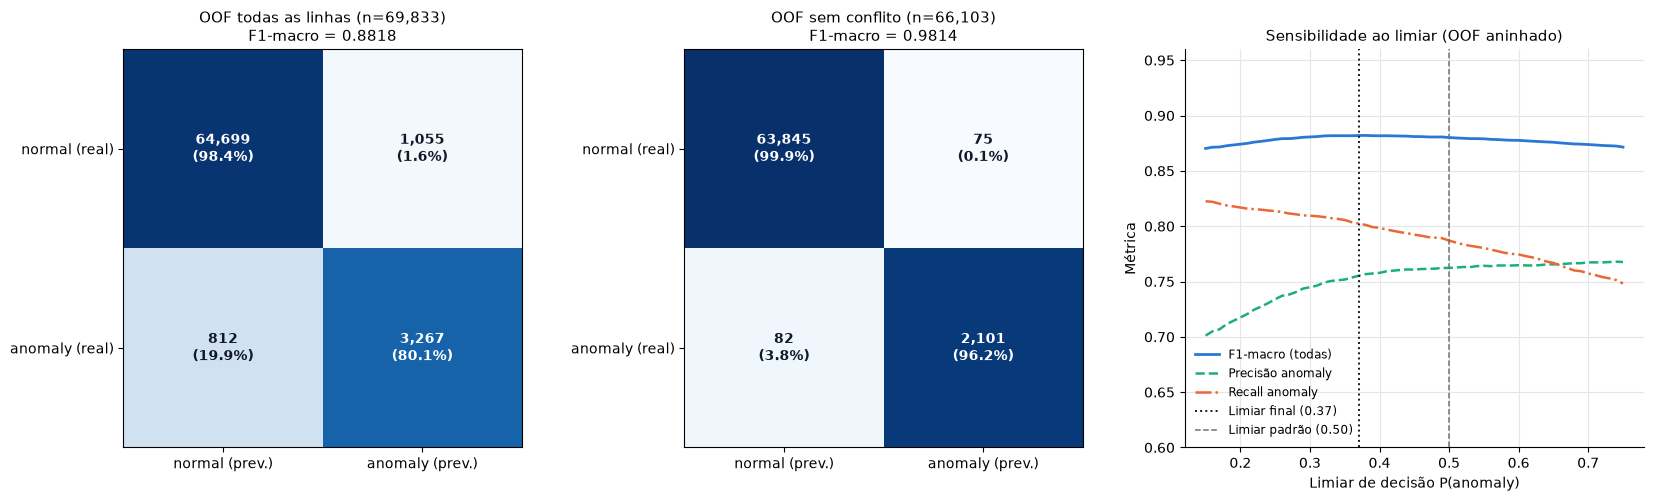

In [8]:
# Membro 2 — 2.2 Decomposição da matriz de confusão (conflitos vs linhas limpas), teto teórico e limiar
import matplotlib.pyplot as plt

perfil_grupos_m2 = y_treino.groupby(grupos_treino).agg(["size", "sum", "nunique"])
n_grupos_confl_m2 = int((perfil_grupos_m2["nunique"] > 1).sum())
assert int(em_conflito_m2.sum()) == 3730 and int(sem_conflito_m2.sum()) == 66103
assert n_grupos_confl_m2 == 1702

# Teto teórico de um oráculo determinístico (0 erros nas 66.103 linhas sem conflito).
g_ids_m2 = grupos_treino.to_numpy()
pred_oraculo_norm_m2 = y_arr_m2.copy()
pred_oraculo_anom_m2 = y_arr_m2.copy()
for g_id, linha_g in perfil_grupos_m2[perfil_grupos_m2["nunique"] > 1].iterrows():
    msk = g_ids_m2 == g_id
    if linha_g["size"] == 3:
        voto_maj = 1 if linha_g["sum"] >= 2 else 0
        pred_oraculo_norm_m2[msk] = voto_maj
        pred_oraculo_anom_m2[msk] = voto_maj
    else:
        pred_oraculo_norm_m2[msk] = 0
        pred_oraculo_anom_m2[msk] = 1

m_all_m2 = resumir_binario_m2(y_arr_m2, pred_oof_aninhado_m2)
m_clean_m2 = resumir_binario_m2(y_arr_m2[sem_conflito_m2], pred_oof_aninhado_m2[sem_conflito_m2])
m_confl_m2 = resumir_binario_m2(y_arr_m2[em_conflito_m2], pred_oof_aninhado_m2[em_conflito_m2])
m_ora_norm_m2 = resumir_binario_m2(y_arr_m2, pred_oraculo_norm_m2)
m_ora_anom_m2 = resumir_binario_m2(y_arr_m2, pred_oraculo_anom_m2)

tabela_recortes_m2 = pd.DataFrame([
    {"Recorte / Referência": "OOF aninhado — Todas as linhas", "Linhas": len(y_arr_m2), **m_all_m2},
    {"Recorte / Referência": "OOF aninhado — Sem conflito (limpas)", "Linhas": int(sem_conflito_m2.sum()), **m_clean_m2},
    {"Recorte / Referência": "OOF aninhado — Grupos conflitantes", "Linhas": int(em_conflito_m2.sum()), **m_confl_m2},
    {"Recorte / Referência": "Oráculo determinístico (empates 1:1 -> normal)", "Linhas": len(y_arr_m2), **m_ora_norm_m2},
    {"Recorte / Referência": "Oráculo determinístico (empates 1:1 -> anomaly)", "Linhas": len(y_arr_m2), **m_ora_anom_m2},
])
cols_rec = [
    "Recorte / Referência", "Linhas", "TN", "FP", "FN", "TP",
    "prec_normal", "rec_normal", "f1_normal",
    "prec_anomaly", "rec_anomaly", "f1_anomaly", "f1_macro",
]
print(f"Grupos conflitantes: {n_grupos_confl_m2} ({em_conflito_m2.sum()} linhas); "
      f"erros em conflitos: {m_confl_m2['FP'] + m_confl_m2['FN']} de {m_all_m2['FP'] + m_all_m2['FN']} totais "
      f"({(m_confl_m2['FP'] + m_confl_m2['FN']) / (m_all_m2['FP'] + m_all_m2['FN']):.1%}).")
display(tabela_recortes_m2[cols_rec].round(4))

# Curva de sensibilidade ao limiar de decisão sobre prob_oof_aninhado_m2.
grade_limiares_m2 = np.round(np.linspace(0.15, 0.75, 61), 2)
curva_limiar_m2 = []
for t in grade_limiares_m2:
    yp_t = (prob_oof_aninhado_m2 >= t).astype(int)
    ma = resumir_binario_m2(y_arr_m2, yp_t)
    mc = resumir_binario_m2(y_arr_m2[sem_conflito_m2], yp_t[sem_conflito_m2])
    curva_limiar_m2.append({
        "limiar": float(t),
        "f1_macro_todas": ma["f1_macro"],
        "f1_macro_limpas": mc["f1_macro"],
        "prec_anomaly_todas": ma["prec_anomaly"],
        "rec_anomaly_todas": ma["rec_anomaly"],
    })
df_curva_limiar_m2 = pd.DataFrame(curva_limiar_m2)

# Figura 2.1: matrizes de confusão (todas vs sem conflito) + curva de limiar.
fig, eixos = plt.subplots(1, 3, figsize=(16.5, 4.9), layout="constrained")


def plotar_cm_m2(ax, cm, titulo):
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0.0, vmax=1.0)
    ax.set_xticks([0, 1], labels=["normal (prev.)", "anomaly (prev.)"])
    ax.set_yticks([0, 1], labels=["normal (real)", "anomaly (real)"])
    ax.set_title(titulo, fontsize=11)
    for i in range(2):
        for j in range(2):
            cor_txt = "white" if cm_norm[i, j] > 0.55 else "#111827"
            ax.text(
                j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]:.1%})",
                ha="center", va="center", color=cor_txt, fontsize=10, fontweight="bold",
            )


cm_todas_m2 = np.array([[m_all_m2["TN"], m_all_m2["FP"]], [m_all_m2["FN"], m_all_m2["TP"]]])
cm_limpas_m2 = np.array([[m_clean_m2["TN"], m_clean_m2["FP"]], [m_clean_m2["FN"], m_clean_m2["TP"]]])

plotar_cm_m2(eixos[0], cm_todas_m2, f"OOF todas as linhas (n={len(y_arr_m2):,})\nF1-macro = {m_all_m2['f1_macro']:.4f}")
plotar_cm_m2(eixos[1], cm_limpas_m2, f"OOF sem conflito (n={int(sem_conflito_m2.sum()):,})\nF1-macro = {m_clean_m2['f1_macro']:.4f}")

ax_curva = eixos[2]
ax_curva.plot(df_curva_limiar_m2["limiar"], df_curva_limiar_m2["f1_macro_todas"], color="#2a78d6", linewidth=2.0, label="F1-macro (todas)")
ax_curva.plot(df_curva_limiar_m2["limiar"], df_curva_limiar_m2["prec_anomaly_todas"], color="#1baf7a", linewidth=1.8, linestyle="--", label="Precisão anomaly")
ax_curva.plot(df_curva_limiar_m2["limiar"], df_curva_limiar_m2["rec_anomaly_todas"], color="#eb6834", linewidth=1.8, linestyle="-.", label="Recall anomaly")
ax_curva.axvline(CONFIG_FINAL["limiar_decisao"], color="#111827", linestyle=":", linewidth=1.4, label=f"Limiar final ({CONFIG_FINAL['limiar_decisao']:.2f})")
ax_curva.axvline(0.50, color="#6b7280", linestyle="--", linewidth=1.1, label="Limiar padrão (0.50)")
ax_curva.set_title("Sensibilidade ao limiar (OOF aninhado)", fontsize=11)
ax_curva.set_xlabel("Limiar de decisão P(anomaly)")
ax_curva.set_ylabel("Métrica")
ax_curva.set_ylim(0.60, 0.96)
ax_curva.grid(color="#e6e6e6", linewidth=0.8)
ax_curva.spines[["top", "right"]].set_visible(False)
ax_curva.legend(loc="lower left", fontsize=8.5, frameon=False)
plt.show()


### 2.3 Anatomia dos erros fora de conflito (perfis de tráfego e faixas de probabilidade)

Excluindo os 1.702 grupos conflitantes, examinamos os erros reais do modelo fora da dobra nas 66.103 linhas limpas:
- **Por perfil de tráfego (`protocol_type`, `flag` e `service`):** identifica em quais protocolos e serviços ocorrem falsos positivos e falsos negativos sem conflito, servindo de diagnóstico descritivo para o relatório (sem alterar nenhum parâmetro do modelo vencedor).
- **Por faixa de probabilidade prevista `P(anomaly)`:** verifica se os erros residuais concentram-se próximos à fronteira de decisão `[0,25; 0,50)` ou se há erros com alta confiança probabilística.


Erros sem conflito por protocol_type:


,tn,fp,fn,tp,anomalias,erros,recall_anomaly,taxa_fp_normal
protocol_type,,,,,,,,
tcp,51000,35,51,1804,1855,86,0.9725,0.0007
udp,11731,23,22,63,85,45,0.7412,0.0020
icmp,1114,17,9,234,243,26,0.9630,0.0150


Erros sem conflito por flag (top 8 categorias com mais erros):


,tn,fp,fn,tp,anomalias,erros,recall_anomaly,taxa_fp_normal
flag,,,,,,,,
sf,56956,51,63,372,435,114,0.8552,0.0009
__ausente__,3738,4,11,130,141,15,0.9220,0.0011
rej,2105,6,5,374,379,11,0.9868,0.0028
rstr,144,6,1,89,90,7,0.9889,0.0400
s0,290,3,2,1059,1061,5,0.9981,0.0102
s2,97,3,0,2,2,3,1.0000,0.0300
rsto,182,1,0,51,51,1,1.0000,0.0055
oth,4,1,0,1,1,1,1.0000,0.2000


Erros sem conflito por service (top 10 categorias com mais erros):


,tn,fp,fn,tp,anomalias,erros,recall_anomaly,taxa_fp_normal
service,,,,,,,,
private,1368,25,18,720,738,43,0.9756,0.0179
__ausente__,4014,11,10,139,149,21,0.9329,0.0027
ftp_data,4064,3,14,43,57,17,0.7544,0.0007
http,35054,6,9,121,130,15,0.9308,0.0002
telnet,720,5,10,77,87,15,0.8851,0.0069
ecr_i,162,6,4,79,83,10,0.9518,0.0357
eco_i,346,8,1,118,119,9,0.9916,0.0226
other,1991,3,6,68,74,9,0.9189,0.0015
ftp,996,1,4,28,32,5,0.8750,0.0010


Distribuição de acertos e erros sem conflito por faixa de probabilidade P(anomaly) OOF:


,n_registros,anomalias_reais,FP,FN,total_erros,pct_erros_limpos
faixa_prob,,,,,,
"[0.00, 0.10)",63320,22,0,22,22,14.0
"[0.10, 0.25)",449,32,0,32,32,20.4
"[0.25, 0.37)",149,24,4,20,24,15.3
"[0.37, 0.50)",93,46,38,8,46,29.3
"[0.50, 0.75)",127,99,28,0,28,17.8
"[0.75, 1.00]",1965,1960,5,0,5,3.2


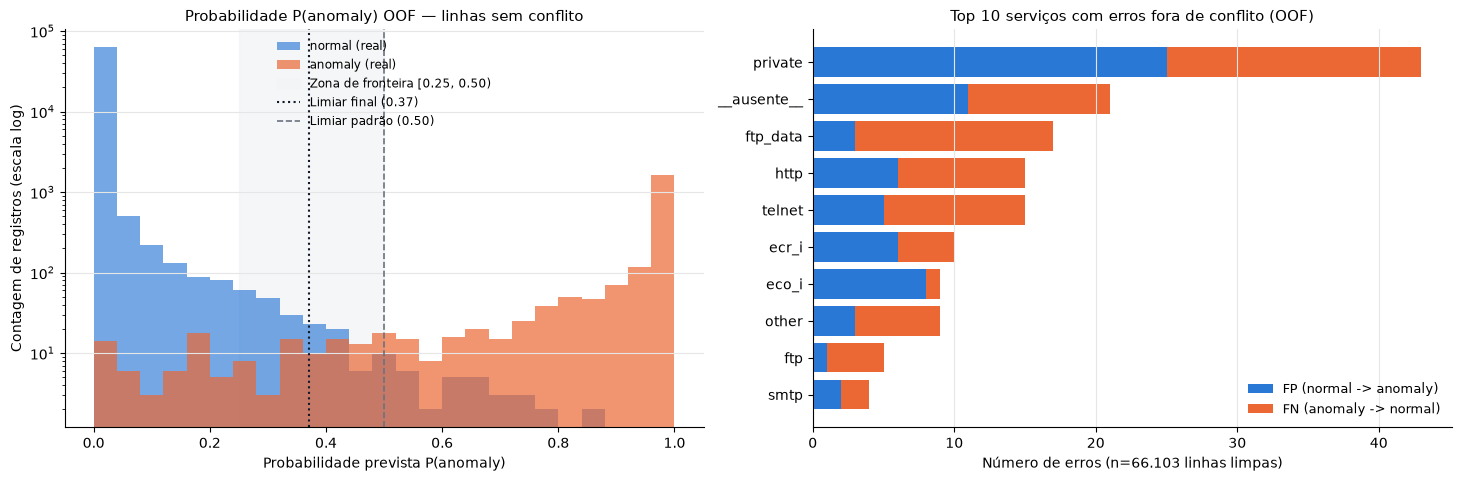

In [9]:
# Membro 2 — 2.3 Diagnóstico de erros nas 66.103 linhas sem conflito (perfis e confiança)
X_limpo_m2 = NormalizarCategorias().transform(X_treino.loc[sem_conflito_m2]).copy()
for col_cat_m2 in COLS_CATEGORICAS:
    X_limpo_m2[col_cat_m2] = X_limpo_m2[col_cat_m2].fillna("__ausente__")

y_limpo_m2 = y_arr_m2[sem_conflito_m2]
yp_limpo_m2 = pred_oof_aninhado_m2[sem_conflito_m2]
prob_limpo_m2 = prob_oof_aninhado_m2[sem_conflito_m2]


def tabela_erros_grupo_m2(coluna, top_n=None):
    df_g = pd.DataFrame({
        coluna: X_limpo_m2[coluna].to_numpy(),
        "tn": ((y_limpo_m2 == 0) & (yp_limpo_m2 == 0)).astype(int),
        "fp": ((y_limpo_m2 == 0) & (yp_limpo_m2 == 1)).astype(int),
        "fn": ((y_limpo_m2 == 1) & (yp_limpo_m2 == 0)).astype(int),
        "tp": ((y_limpo_m2 == 1) & (yp_limpo_m2 == 1)).astype(int),
    }).groupby(coluna, sort=False).sum()
    df_g["anomalias"] = df_g["fn"] + df_g["tp"]
    df_g["erros"] = df_g["fp"] + df_g["fn"]
    df_g["recall_anomaly"] = np.where(df_g["anomalias"] > 0, df_g["tp"] / df_g["anomalias"], np.nan)
    df_g["taxa_fp_normal"] = np.where((df_g["tn"] + df_g["fp"]) > 0, df_g["fp"] / (df_g["tn"] + df_g["fp"]), np.nan)
    df_g = df_g.sort_values(["erros", "anomalias"], ascending=[False, False])
    return df_g.head(top_n) if top_n else df_g


tab_proto_m2 = tabela_erros_grupo_m2("protocol_type")
tab_flag_m2 = tabela_erros_grupo_m2("flag", top_n=8)
tab_service_m2 = tabela_erros_grupo_m2("service", top_n=10)

print("Erros sem conflito por protocol_type:")
display(tab_proto_m2.round(4))
print("Erros sem conflito por flag (top 8 categorias com mais erros):")
display(tab_flag_m2.round(4))
print("Erros sem conflito por service (top 10 categorias com mais erros):")
display(tab_service_m2.round(4))

# Análise por faixa de probabilidade prevista P(anomaly) nas linhas sem conflito.
bordas_m2 = [0.0, 0.10, 0.25, 0.37, 0.50, 0.75, 1.0001]
rotulos_faixa_m2 = ["[0.00, 0.10)", "[0.10, 0.25)", "[0.25, 0.37)", "[0.37, 0.50)", "[0.50, 0.75)", "[0.75, 1.00]"]
faixas_m2 = pd.cut(prob_limpo_m2, bins=bordas_m2, labels=rotulos_faixa_m2, right=False)

df_faixas_m2 = pd.DataFrame({
    "faixa_prob": faixas_m2,
    "n_registros": 1,
    "anomalias_reais": y_limpo_m2,
    "FP": ((y_limpo_m2 == 0) & (yp_limpo_m2 == 1)).astype(int),
    "FN": ((y_limpo_m2 == 1) & (yp_limpo_m2 == 0)).astype(int),
}).groupby("faixa_prob", observed=False).sum()
df_faixas_m2["total_erros"] = df_faixas_m2["FP"] + df_faixas_m2["FN"]
df_faixas_m2["pct_erros_limpos"] = (
    100.0 * df_faixas_m2["total_erros"] / max(1, int(df_faixas_m2["total_erros"].sum()))
).round(1)
print("Distribuição de acertos e erros sem conflito por faixa de probabilidade P(anomaly) OOF:")
display(df_faixas_m2)

# Figura 2.2: distribuição de probabilidades OOF por classe real + serviços com mais erros.
fig, eixos = plt.subplots(1, 2, figsize=(14.5, 4.7), layout="constrained")

bins_hist_m2 = np.linspace(0.0, 1.0, 26)
eixos[0].hist(prob_limpo_m2[y_limpo_m2 == 0], bins=bins_hist_m2, alpha=0.65, color="#2a78d6", label="normal (real)")
eixos[0].hist(prob_limpo_m2[y_limpo_m2 == 1], bins=bins_hist_m2, alpha=0.70, color="#eb6834", label="anomaly (real)")
eixos[0].axvspan(0.25, 0.50, color="#f3f4f6", alpha=0.8, zorder=0, label="Zona de fronteira [0.25, 0.50)")
eixos[0].axvline(CONFIG_FINAL["limiar_decisao"], color="#111827", linestyle=":", linewidth=1.5, label=f"Limiar final ({CONFIG_FINAL['limiar_decisao']:.2f})")
eixos[0].axvline(0.50, color="#6b7280", linestyle="--", linewidth=1.2, label="Limiar padrão (0.50)")
eixos[0].set_yscale("log")
eixos[0].set_title("Probabilidade P(anomaly) OOF — linhas sem conflito", fontsize=11)
eixos[0].set_xlabel("Probabilidade prevista P(anomaly)")
eixos[0].set_ylabel("Contagem de registros (escala log)")
eixos[0].grid(axis="y", color="#e6e6e6", linewidth=0.8)
eixos[0].spines[["top", "right"]].set_visible(False)
eixos[0].legend(loc="upper center", fontsize=8.5, frameon=False)

top_srv_plot_m2 = tab_service_m2.iloc[::-1]
pos_srv_m2 = np.arange(len(top_srv_plot_m2))
eixos[1].barh(pos_srv_m2, top_srv_plot_m2["fp"], color="#2a78d6", label="FP (normal -> anomaly)")
eixos[1].barh(pos_srv_m2, top_srv_plot_m2["fn"], left=top_srv_plot_m2["fp"], color="#eb6834", label="FN (anomaly -> normal)")
eixos[1].set_yticks(pos_srv_m2, labels=top_srv_plot_m2.index)
eixos[1].set_title("Top 10 serviços com erros fora de conflito (OOF)", fontsize=11)
eixos[1].set_xlabel("Número de erros (n=66.103 linhas limpas)")
eixos[1].grid(axis="x", color="#e6e6e6", linewidth=0.8)
eixos[1].spines[["top", "right"]].set_visible(False)
eixos[1].legend(loc="lower right", fontsize=9, frameon=False)
plt.show()


### 2.4 Limitações metodológicas e quadro oficial reservado para o teste (`teste_sem_rotulo.csv`)

Todas as métricas e matrizes desta seção vêm exclusivamente de validação interna sobre `data/treino.csv`. O conjunto oficial `data/teste_sem_rotulo.csv` não contém a coluna `class` e não foi lido ou consultado em nenhuma etapa do diagnóstico. O quadro final de avaliação oficial permanece reservado até a divulgação do gabarito e do ranking pela professora após a entrega de 28/11/2026.


In [10]:
# Membro 2 — 2.4 Conferência de isolamento do teste e quadro reservado para resultados oficiais
assert X_treino.shape == (69833, 46)
assert len(prob_oof_aninhado_m2) == len(X_treino)
assert "class" not in pd.read_csv(DIR_DADOS / "teste_sem_rotulo.csv", nrows=0).columns

comparacao_ambientes_m2 = pd.DataFrame([
    {
        "Aspecto": "Conjunto de dados",
        "Validação Interna (esta seção)": "data/treino.csv (69.833 linhas em 5 dobras OOF)",
        "Avaliação Oficial do Teste (pós-28/11)": "data/teste_sem_rotulo.csv (24.333 linhas)",
    },
    {
        "Aspecto": "Disponibilidade de rótulos",
        "Validação Interna (esta seção)": "Sim (coluna class; 5,84% anomaly)",
        "Avaliação Oficial do Teste (pós-28/11)": "Não disponível à equipe (gabarito exclusivo da professora)",
    },
    {
        "Aspecto": "Registros usados por ajuste",
        "Validação Interna (esta seção)": "~52.884 linhas por dobra após filtro de conflitos",
        "Avaliação Oficial do Teste (pós-28/11)": "66.103 linhas no pipeline final (todo o treino filtrado)",
    },
    {
        "Aspecto": "Impacto de conflitos na métrica",
        "Validação Interna (esta seção)": "1.702 grupos conflitantes limitam o oráculo a ~0,869–0,905",
        "Avaliação Oficial do Teste (pós-28/11)": "Medida diretamente pela professora sobre o gabarito oficial",
    },
    {
        "Aspecto": "Papel metodológico",
        "Validação Interna (esta seção)": "Estimar generalização sem vazamento e diagnosticar erros",
        "Avaliação Oficial do Teste (pós-28/11)": "Calcular F1-macro oficial, métricas por classe e ranking final",
    },
])
print("Distinção entre validação interna e avaliação oficial no teste:")
display(comparacao_ambientes_m2)

quadro_oficial_reservado_m2 = pd.DataFrame([
    {
        "Métrica oficial": "F1-macro (ranking oficial)",
        "Validação interna OOF (todas)": f"{df_dobras_m2['f1_macro'].mean():.4f} ± {df_dobras_m2['f1_macro'].std():.4f}",
        "Validação interna OOF (sem conflito)": f"{m_clean_m2['f1_macro']:.4f}",
        "Teste oficial (pós-28/11 — professora)": "Pendente (aguardando divulgação após 28/11/2026)",
    },
    {
        "Métrica oficial": "Precisão / Recall / F1 — normal",
        "Validação interna OOF (todas)": f"{agg_oof_m2['prec_normal']:.4f} / {agg_oof_m2['rec_normal']:.4f} / {agg_oof_m2['f1_normal']:.4f}",
        "Validação interna OOF (sem conflito)": f"{m_clean_m2['prec_normal']:.4f} / {m_clean_m2['rec_normal']:.4f} / {m_clean_m2['f1_normal']:.4f}",
        "Teste oficial (pós-28/11 — professora)": "Pendente (aguardando divulgação após 28/11/2026)",
    },
    {
        "Métrica oficial": "Precisão / Recall / F1 — anomaly",
        "Validação interna OOF (todas)": f"{agg_oof_m2['prec_anomaly']:.4f} / {agg_oof_m2['rec_anomaly']:.4f} / {agg_oof_m2['f1_anomaly']:.4f}",
        "Validação interna OOF (sem conflito)": f"{m_clean_m2['prec_anomaly']:.4f} / {m_clean_m2['rec_anomaly']:.4f} / {m_clean_m2['f1_anomaly']:.4f}",
        "Teste oficial (pós-28/11 — professora)": "Pendente (aguardando divulgação após 28/11/2026)",
    },
    {
        "Métrica oficial": "Posição do Grupo 10 no ranking",
        "Validação interna OOF (todas)": "Não aplicável (métrica interna)",
        "Validação interna OOF (sem conflito)": "Não aplicável (métrica interna)",
        "Teste oficial (pós-28/11 — professora)": "Pendente (divulgação pela professora)",
    },
])
print("Quadro oficial reservado para o conjunto de teste sem rótulo:")
display(quadro_oficial_reservado_m2)


Distinção entre validação interna e avaliação oficial no teste:


,Aspecto,Validação Interna (esta seção),Avaliação Oficial do Teste (pós-28/11)
0,Conjunto de dados,data/treino.csv (69.833 linhas em 5 dobras OOF),data/teste_sem_rotulo.csv (24.333 linhas)
1,Disponibilidade de rótulos,"Sim (coluna class; 5,84% anomaly)",Não disponível à equipe (gabarito exclusivo da...
2,Registros usados por ajuste,~52.884 linhas por dobra após filtro de conflitos,66.103 linhas no pipeline final (todo o treino...
3,Impacto de conflitos na métrica,1.702 grupos conflitantes limitam o oráculo a ...,Medida diretamente pela professora sobre o gab...
4,Papel metodológico,Estimar generalização sem vazamento e diagnost...,"Calcular F1-macro oficial, métricas por classe..."


Quadro oficial reservado para o conjunto de teste sem rótulo:


,Métrica oficial,Validação interna OOF (todas),Validação interna OOF (sem conflito),Teste oficial (pós-28/11 — professora)
0,F1-macro (ranking oficial),0.8818 ± 0.0007,0.9814,Pendente (aguardando divulgação após 28/11/2026)
1,Precisão / Recall / F1 — normal,0.9876 / 0.9840 / 0.9858,0.9987 / 0.9988 / 0.9988,Pendente (aguardando divulgação após 28/11/2026)
2,Precisão / Recall / F1 — anomaly,0.7559 / 0.8009 / 0.7778,0.9655 / 0.9624 / 0.9640,Pendente (aguardando divulgação após 28/11/2026)
3,Posição do Grupo 10 no ranking,Não aplicável (métrica interna),Não aplicável (métrica interna),Pendente (divulgação pela professora)


### Resultados e justificativa — Seção 2

**Origem das métricas e garantia contra vazamento (2.1).** Todas as métricas desta seção são estimadas exclusivamente por validação interna em `data/treino.csv` (`69.833` linhas, `ASSINATURA_DOBRAS = 8a814c72d149c698`), sem nenhuma leitura dos atributos ou rótulos do conjunto de teste (que não possui `class`). A estimativa principal provém da validação cruzada aninhada fora da dobra (5 dobras externas x 3 dobras internas por grupos):

| Métrica (validação interna OOF) | Média ± dp (5 dobras) | Agregado OOF (`n=69.833`) | IC 95% (bootstrap por grupos) | Suporte |
|---|---:|---:|---:|---:|
| Precisão — `normal` | 0,9876 ± 0,0005 | 0,9876 | [0,9869; 0,9883] | 65.754 |
| Recall — `normal` | 0,9840 ± 0,0007 | 0,9840 | [0,9832; 0,9846] | 65.754 |
| F1 — `normal` | 0,9858 ± 0,0001 | 0,9858 | [0,9856; 0,9860] | 65.754 |
| Precisão — `anomaly` | 0,7560 ± 0,0059 | 0,7559 | [0,7495; 0,7619] | 4.079 |
| Recall — `anomaly` | 0,8009 ± 0,0075 | 0,8009 | [0,7896; 0,8134] | 4.079 |
| F1 — `anomaly` | 0,7778 ± 0,0014 | 0,7778 | [0,7732; 0,7827] | 4.079 |
| **F1-macro (métrica oficial)** | **0,8818 ± 0,0007** | **0,8818** | **[0,8794; 0,8843]** | 69.833 |
| Acurácia balanceada | 0,8924 ± 0,0034 | 0,8924 | [0,8871; 0,8984] | 69.833 |
| ROC-AUC / PR-AUC (`anomaly`) | 0,9061 / 0,6520 | 0,9061 / 0,6519 | — | 69.833 / 4.079 |
| Acurácia (apenas complementar) | 0,9733 ± 0,0002 | 0,9733 | [0,9729; 0,9737] | 69.833 |

Entre as 5 dobras externas, o `F1-macro` permanece altamente estável entre `0,8810` (dobra 5) e `0,8828` (dobra 3). A avaliação da `CONFIG_FINAL` congelada nas mesmas 5 dobras OOF confirma consistência (`F1-macro = 0,8817`, `1.064 FP / 807 FN`; `0,9809` sem conflito). Em contraste, o contraexemplo de ressubstituição no próprio treino (`pipeline_final` avaliado sobre `X_treino`) infla artificialmente o `F1-macro` para `0,8921` no agregado total e **`0,9999`** (`1 FP / 0 FN`) nas linhas limpas, ilustrando por que métricas no conjunto de treino não medem generalização.

**Matriz de confusão e separação entre conflitos e dados limpos (2.2).** Na matriz agregada fora da dobra (`69.833` linhas), registram-se `TN = 64.699` (98,4%), `FP = 1.055` (1,6%), `FN = 812` (19,9%) e `TP = 3.267` (80,1%), totalizando `1.867` erros:
- **Peso dos grupos conflitantes:** `1.710` desses `1.867` erros (`91,6%`) concentram-se nos `1.702` grupos conflitantes (`3.730` registros idênticos nos 46 preditores com rótulos opostos), onde qualquer classificador determinístico erra ao menos um registro por grupo e mesmo um oráculo perfeito fica limitado entre `0,8693` (empates 1:1 como `normal`) e `0,9048` (empates 1:1 como `anomaly`).
- **Desempenho real nas linhas limpas (`66.103` registros sem conflito):** `TN = 63.845` (99,9%), `FP = 75` (0,1%), `FN = 82` (3,8%) e `TP = 2.101` (96,2%), alcançando **`F1-macro = 0,9814`** (`F1 normal = 0,9988`, `Precisão / Recall / F1 anomaly = 0,9655 / 0,9624 / 0,9640`) e apenas `157` erros totais.
- **Papel do ajuste interno de limiar:** como o filtro `sem_conflitos` reduz a prevalência de `anomaly` no treino de `5,84%` para `3,30%`, manter o limiar padrão `0,50` torna o classificador excessivamente conservador (`31 FP / 126 FN` sem conflito; `F1-macro` geral `0,8800`). O limiar interno (`0,34`–`0,45` nas dobras) equilibra `FP` e `FN` (`75 / 82` sem conflito) e eleva o recall de `anomaly` para `0,8009` no geral e `0,9624` nos registros limpos.

**Diagnóstico dos `157` erros fora de conflito (2.3).**
- **Perfis de tráfego:** em `protocol_type`, `tcp` soma `86` erros (`recall_anomaly = 0,9725`), `udp` soma `45` erros (menor taxa de detecção, `recall_anomaly = 0,7412` em `85` anomalias) e `icmp` soma `26` erros (`recall = 0,9630`, `taxa_fp_normal = 0,0150`). Por `flag`, `sf` concentra `114` erros (`51 FP / 63 FN`, `recall = 0,8552`), seguida por `__ausente__` (`15` erros) e `rej` (`11` erros). Entre os serviços, destacam-se `private` (`43` erros: `25 FP / 18 FN`), `__ausente__` (`21`), `ftp_data` (`17`, `recall = 0,7544`), `http` (`15` em mais de 35 mil conexões, `taxa_fp = 0,0002`) e `telnet` (`15`, `recall = 0,8851`).
- **Faixas de probabilidade `P(anomaly)`:** `44,6%` dos erros limpos (`70` de `157`) ocorrem na zona de fronteira `[0,25; 0,50)` (`24` em `[0,25; 0,37)` e `46` em `[0,37; 0,50)`, refletindo a variação entre limiares internos `0,34`–`0,45` por dobra), enquanto erros em alta confiança são raros (`22` FNs em `63.320` registros com `P < 0,10` e `5` FPs em `1.965` registros com `P >= 0,75`).

**Limitações e reserva dos resultados oficiais do teste (2.4).**
1. **Separação estrita do teste oficial:** nenhuma métrica desta seção usa `data/teste_sem_rotulo.csv`. O quadro oficial da seção 2.4 (`F1-macro`, Precisão/Recall/F1 por classe e ranking do Grupo 10) permanece reservado e será preenchido somente após a divulgação dos resultados pela professora depois de 28/11/2026.
2. **Otimismo residual de escolhas acumuladas:** as combinações e famílias de modelos comparadas até a etapa 3 reutilizaram a mesma partição base em `treino.csv`.
3. **Escala do treino final vs. calibração:** cada dobra externa ajusta o modelo em `~52.884` linhas filtradas (e a seleção interna de limiar em `~2/3` disso), ao passo que o `pipeline_final` ajusta em `66.103` linhas filtradas.
4. **Incerteza de distribuição no teste oficial:** se a proporção de registros conflitantes ou o perfil de ruído em `teste_sem_rotulo.csv` diferirem de `treino.csv`, o `F1-macro` oficial aproximará mais o regime limpo (`~0,98`) ou o regime com ruído (`~0,88`). Os três sinais operacionais seguem excluídos preventivamente conforme documentado na etapa 1–3.

**Uso de IA.** A estruturação do diagnóstico, implementação em Python e revisão textual desta seção tiveram apoio de ferramenta de IA generativa (Antigravity / modelo Gemini), cabendo à equipe a verificação das execuções e a responsabilidade integral pelas interpretações apresentadas.


## Seção 3 — Explicabilidade do vencedor (Arthur Soares Rolla)

**Tarefa:** Escolher e aplicar uma técnica de explicabilidade compatível com o vencedor, como importância por permutação em validação ou SHAP. Explicar os atributos relevantes, efeitos de correlação e limitações; não usar o teste para ajustar ou selecionar o modelo.

**Entregável:** Gráficos e interpretação técnica para o relatório e a apresentação, sem confundir importância preditiva com causalidade.


### 3.1 Modelo e dados usados na explicação

Explicamos a Random Forest final definida pelo grupo, mantendo seu pré-processamento e o limiar de decisão de 0,37. Usamos uma amostra dos registros de treino que permaneceram após o filtro de conflitos. A análise descreve o comportamento do modelo ajustado e não serve como estimativa de desempenho em dados novos. O teste oficial não é utilizado.

In [11]:
#Referências ao modelo já ajustado
pipe_explicacao_m3 = pipeline_final.pipeline_
floresta_m3 = pipe_explicacao_m3.named_steps["modelo"]
prep_explicacao_m3 = pipe_explicacao_m3[:-1]

#Amostra reproduzível do treino filtrado
X_base_m3, y_base_m3 = filtrar_linhas_treino(X_treino, y_treino, CONFIG_FINAL["linhas_treino"])
X_explicacao_m3 = X_base_m3.sample(n=min(200, len(X_base_m3)), random_state=SEMENTE)
Z_explicacao_m3 = prep_explicacao_m3.transform(X_explicacao_m3)
nomes_atributos_m3 = pipe_explicacao_m3.named_steps["imputacao_codificacao"].get_feature_names_out()
assert Z_explicacao_m3.shape[1] == len(nomes_atributos_m3)
assert np.isfinite(Z_explicacao_m3).all()

print("Modelo:", type(floresta_m3).__name__)
print("Árvores:", len(floresta_m3.estimators_))
print("Limiar de decisão:", CONFIG_FINAL["limiar_decisao"])
print("Amostra para explicação:", Z_explicacao_m3.shape)
display(y_base_m3.loc[X_explicacao_m3.index].map({0: "normal", 1: "anomaly"}).value_counts())

Modelo: RandomForestClassifier
Árvores: 300
Limiar de decisão: 0.37
Amostra para explicação: (200, 67)


class
normal     197
anomaly      3
Name: count, dtype: int64

### 3.2 Cálculo dos valores SHAP

Usamos SHAP para calcular como cada atributo contribui para a probabilidade de anomaly produzida pela floresta. Valores positivos aumentam essa probabilidade em relação ao valor de referência; negativos diminuem. A referência usa 100 registros do treino filtrado. Os resultados dependem dessa referência e descrevem associações aprendidas pelo modelo, não relações de causa e efeito.

In [12]:
import warnings
from tqdm import TqdmWarning

with warnings.catch_warnings():
    warnings.simplefilter("ignore", TqdmWarning)
    import shap

print("Versão do SHAP:", shap.__version__)
#Referência retirada somente do treino
X_referencia_m3 = X_base_m3.sample(n=min(100, len(X_base_m3)), random_state=SEMENTE + 1)
Z_referencia_m3 = prep_explicacao_m3.transform(X_referencia_m3)
explicador_m3 = shap.TreeExplainer(
    floresta_m3,
    data=Z_referencia_m3,
    feature_perturbation="interventional",
    model_output="probability"
)
shap_completo_m3 = explicador_m3(Z_explicacao_m3, check_additivity=True)
#Seleciona as contribuições para a classe
indice_anomaly_m3 = list(floresta_m3.classes_).index(1)
shap_anomaly_m3 = shap_completo_m3[:, :, indice_anomaly_m3]
shap_anomaly_m3.feature_names = list(nomes_atributos_m3)

#Confere a reconstrução sem modificar os valores SHAP
prob_anomaly_m3 = floresta_m3.predict_proba(Z_explicacao_m3)[:, indice_anomaly_m3]
prob_reconstruida_m3 = shap_anomaly_m3.base_values + shap_anomaly_m3.values.sum(axis=1)
erro_aditividade_m3 = np.abs(prob_anomaly_m3 - prob_reconstruida_m3)

print("Valores SHAP:", shap_anomaly_m3.values.shape)
print("Maior diferença de reconstrução:", erro_aditividade_m3.max())
assert np.isfinite(erro_aditividade_m3).all()
assert erro_aditividade_m3.max() < 0.0001
print("Reconstrução dentro da tolerância absoluta de 0,0001.")

Versão do SHAP: 0.53.0


Valores SHAP: (200, 67)
Maior diferença de reconstrução: 6.670218320148358e-05
Reconstrução dentro da tolerância absoluta de 0,0001.


A reconstrução apresentou diferença máxima de aproximadamente 0,0000667. Conferimos que o valor de referência coincide com a probabilidade média da floresta nos dados de referência, mas a origem do desvio não foi determinada. Mantivemos os valores SHAP sem correções e usamos tolerância absoluta de 0,0001 na conferência. Essa tolerância foi definida após observar a discrepância e não faz parte do ajuste do modelo.

### 3.3 Gráficos e análise dos atributos

Ordenamos os atributos pela média do valor absoluto de SHAP nos 200 registros analisados. O gráfico de barras mostra a intensidade média das contribuições. No beeswarm, valores SHAP positivos aumentam a probabilidade de anomaly e negativos diminuem, em relação à referência. A cor indica o valor do atributo. Como a amostra contém 197 registros normais e 3 anomalias, a análise representa principalmente conexões normais.

,atributo,media_shap_absoluto
2,dst_bytes,0.012232
53,service_private,0.005996
35,dst_host_rerror_rate,0.004806
1,src_bytes,0.004762
37,protocol_type_icmp,0.004532
18,count,0.004388
24,same_srv_rate,0.003858
19,srv_count,0.003830
27,dst_host_count,0.003679
65,flag_sf,0.003618


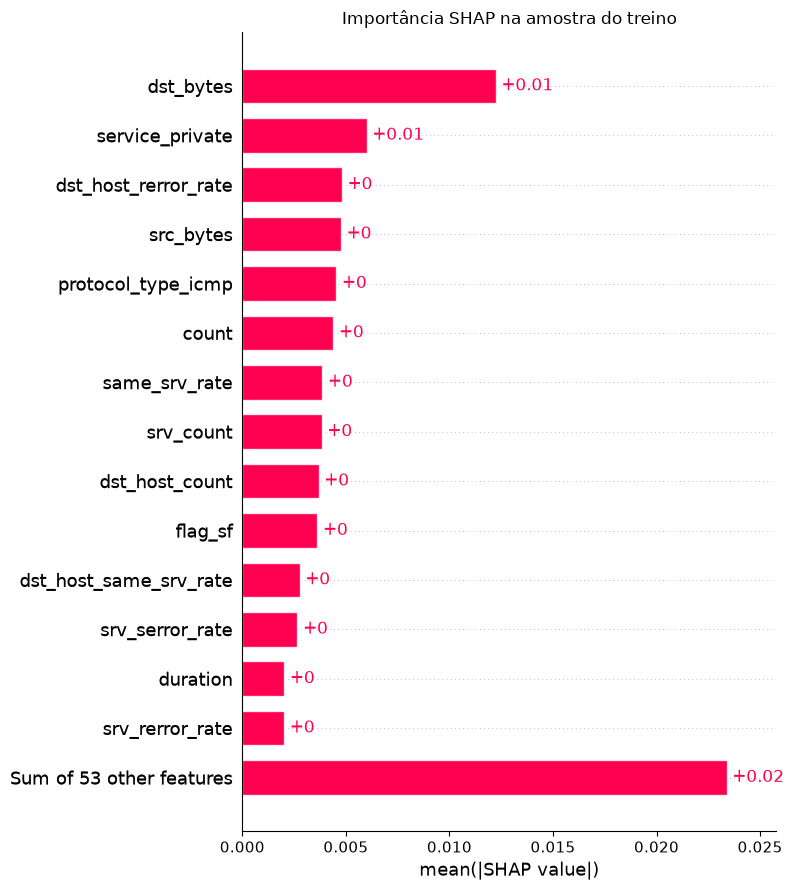

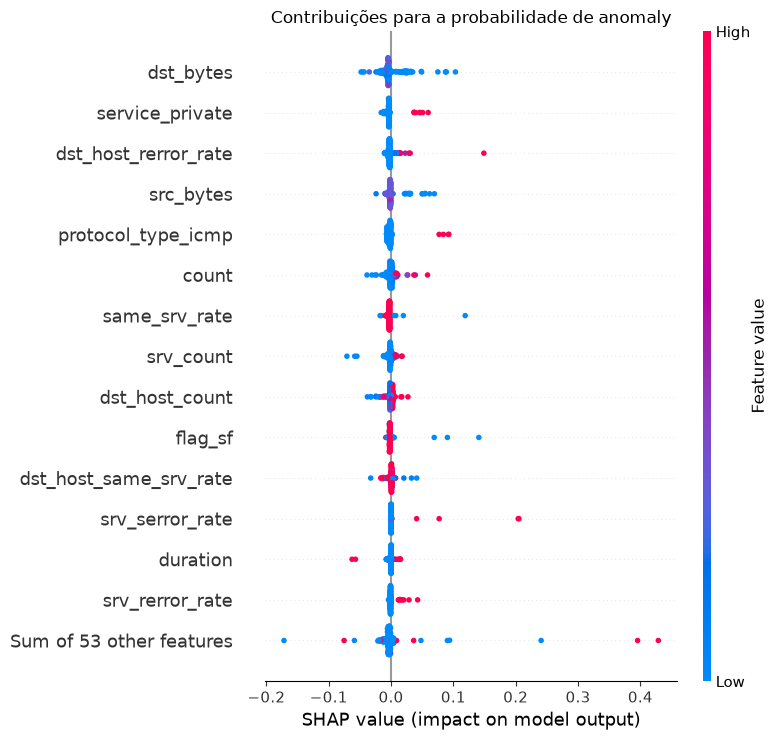

In [13]:
import matplotlib.pyplot as plt
importancia_shap_m3 = pd.DataFrame({
    "atributo": nomes_atributos_m3,
    "media_shap_absoluto": np.abs(shap_anomaly_m3.values).mean(axis=0)
}).sort_values("media_shap_absoluto", ascending=False)

display(importancia_shap_m3.head(15))
shap.plots.bar(shap_anomaly_m3, max_display=15, show=False)
plt.title("Importância SHAP na amostra do treino")
plt.tight_layout()
plt.show()
plt.close("all")

shap.plots.beeswarm(shap_anomaly_m3, max_display=15, show=False)
plt.title("Contribuições para a probabilidade de anomaly")
plt.tight_layout()
plt.show()
plt.close("all")

Na amostra aleatória analisada (`197 normal` e `3 anomaly`), `dst_bytes` teve a maior contribuição média absoluta para a probabilidade de `anomaly` (`0,012232`), seguido de `service_private` (`0,005996`), `dst_host_rerror_rate` (`0,004806`), `src_bytes` (`0,004762`) e `protocol_type_icmp` (`0,004532`). Esses valores medem a intensidade das contribuições na escala de probabilidade da classe `anomaly`. O agrupamento final dos atributos restantes aparece como uma única linha resumida nos gráficos e não corresponde a uma variável isolada da base.

No *beeswarm*, a presença de `service_private` e `protocol_type_icmp` aparece associada a contribuições positivas nos registros mostrados, assim como taxas de erro mais altas (`dst_host_rerror_rate`, `srv_serror_rate`). Esses padrões descrevem o comportamento desta floresta na amostra e dependem do conjunto de referência utilizado e dos atributos após imputação e codificação One-Hot.

### 3.4 Complemento metodológico: amostra estratificada e importância por permutação fora da dobra

A amostra aleatória da seção 3.1 preserva a prevalência do treino filtrado (`3,30%` de `anomaly`, resultando em 197 registros `normal` e 3 `anomaly`). Para ampliar a leitura do comportamento da floresta em ataques sem perder a coerência do método:

1. **SHAP em amostra estratificada (`100 normal + 100 anomaly`, semente `42`):** reutilizamos o mesmo `explicador_m3` e a mesma referência de 100 registros do treino filtrado para medir as contribuições em uma amostra equilibrada pelas duas classes.
2. **Importância por permutação fora da dobra (`permutation_importance` nos 46 preditores brutos):** ajustamos um modelo independente com `CONFIG_FINAL` apenas no treino da **dobra externa 1** (`dobras[0]`, agrupada e estratificada) e medimos a queda média no **F1-macro oficial** (5 repetições, semente `42`) na validação correspondente. Avaliar nos atributos anteriores ao One-Hot evita diluir a importância de variáveis categóricas (`service` e `flag`) em múltiplas colunas binárias e mede impacto preditivo fora do ajuste.

SHAP estratificado (100 normal + 100 anomaly) | erro máximo aditividade: 0.0000667


Dobra 1 OOF | F1-macro base: 0.8814 | linhas val.: 13967


,atributo,media_shap_absoluto
0,dst_bytes,0.056638
1,srv_serror_rate,0.053427
2,flag_sf,0.052752
3,dst_host_srv_serror_rate,0.047603
4,src_bytes,0.025640
5,dst_host_rerror_rate,0.025130
6,count,0.022736
7,dst_host_same_srv_rate,0.020245
8,flag_s0,0.020188
9,same_srv_rate,0.020187


,atributo,queda_f1_macro_media,desvio_padrao
0,protocol_type,0.031879,0.000954
1,dst_host_srv_serror_rate,0.027341,0.001934
2,dst_bytes,0.013942,0.000665
3,service,0.013860,0.001135
4,src_bytes,0.007654,0.001453
5,srv_count,0.006770,0.001504
6,hot,0.005797,0.000444
7,duration,0.004908,0.000388
8,dst_host_diff_srv_rate,0.003588,0.000524
9,dst_host_same_srv_rate,0.003532,0.000759


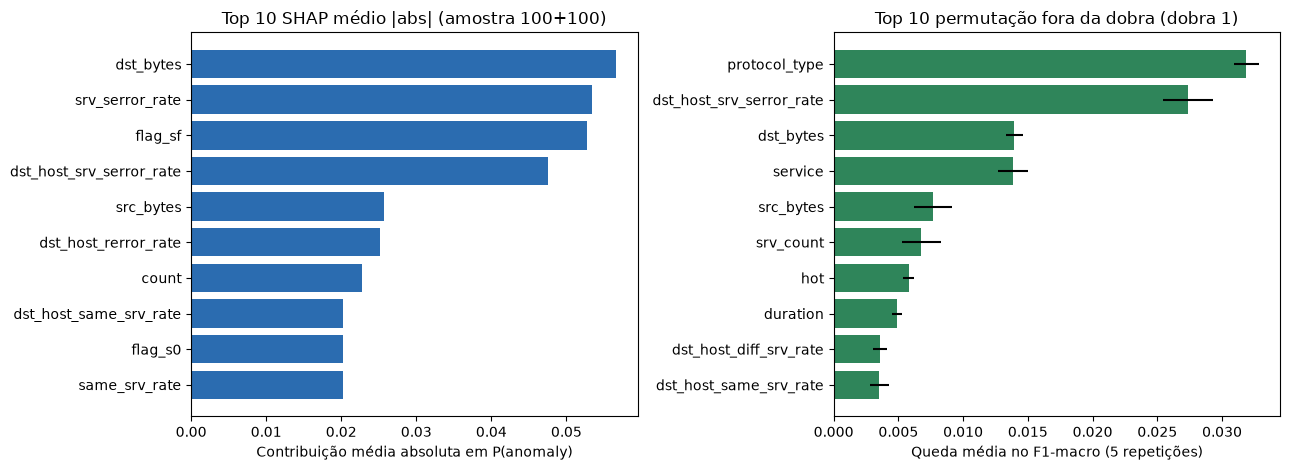

In [14]:
# Seção 3 — 3.4 Amostra estratificada para SHAP e importância por permutação fora da dobra
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

# 1) Amostra estratificada (100 normal + 100 anomaly) sobre o mesmo explicador_m3
X_norm_m3 = X_base_m3.loc[y_base_m3 == 0].sample(n=100, random_state=SEMENTE)
X_anom_m3 = X_base_m3.loc[y_base_m3 == 1].sample(n=100, random_state=SEMENTE)
X_estrat_m3 = pd.concat([X_norm_m3, X_anom_m3], axis=0)
Z_estrat_m3 = prep_explicacao_m3.transform(X_estrat_m3)

shap_estrat_m3 = explicador_m3(Z_estrat_m3, check_additivity=True)[:, :, indice_anomaly_m3]
shap_estrat_m3.feature_names = list(nomes_atributos_m3)
prob_estrat_m3 = floresta_m3.predict_proba(Z_estrat_m3)[:, indice_anomaly_m3]
erro_estrat_m3 = np.abs(prob_estrat_m3 - (shap_estrat_m3.base_values + shap_estrat_m3.values.sum(axis=1)))
assert np.isfinite(erro_estrat_m3).all() and erro_estrat_m3.max() < 0.0001
print(f"SHAP estratificado (100 normal + 100 anomaly) | erro máximo aditividade: {erro_estrat_m3.max():.7f}")

importancia_shap_estrat_m3 = pd.DataFrame({
    "atributo": nomes_atributos_m3,
    "media_shap_absoluto": np.abs(shap_estrat_m3.values).mean(axis=0),
}).sort_values("media_shap_absoluto", ascending=False).reset_index(drop=True)

# 2) Importância por permutação fora da dobra (dobra externa 1, 46 preditores brutos, F1-macro)
idx_tr_f1_m3, idx_va_f1_m3 = dobras[0]
est_f1_m3 = PipelineFinalIDS(CONFIG_FINAL).fit(X_treino.iloc[idx_tr_f1_m3], y_treino.iloc[idx_tr_f1_m3])
scorer_f1_m3 = make_scorer(metricas_f1_macro)
f1_base_f1_m3 = metricas_f1_macro(y_treino.iloc[idx_va_f1_m3], est_f1_m3.predict(X_treino.iloc[idx_va_f1_m3]))

perm_m3 = permutation_importance(
    est_f1_m3,
    X_treino.iloc[idx_va_f1_m3],
    y_treino.iloc[idx_va_f1_m3],
    scoring=scorer_f1_m3,
    n_repeats=5,
    random_state=SEMENTE,
    n_jobs=1,
)

importancia_perm_m3 = pd.DataFrame({
    "atributo": X_treino.columns,
    "queda_f1_macro_media": perm_m3.importances_mean,
    "desvio_padrao": perm_m3.importances_std,
}).sort_values("queda_f1_macro_media", ascending=False).reset_index(drop=True)

print(f"Dobra 1 OOF | F1-macro base: {f1_base_f1_m3:.4f} | linhas val.: {len(idx_va_f1_m3)}")
display(importancia_shap_estrat_m3.head(10))
display(importancia_perm_m3.head(10))

fig_m3, axes_m3 = plt.subplots(1, 2, figsize=(13, 4.8))
top_shap_e = importancia_shap_estrat_m3.head(10).iloc[::-1]
axes_m3[0].barh(top_shap_e["atributo"], top_shap_e["media_shap_absoluto"], color="#2b6cb0")
axes_m3[0].set_title("Top 10 SHAP médio |abs| (amostra 100+100)")
axes_m3[0].set_xlabel("Contribuição média absoluta em P(anomaly)")

top_perm = importancia_perm_m3.head(10).iloc[::-1]
axes_m3[1].barh(top_perm["atributo"], top_perm["queda_f1_macro_media"], xerr=top_perm["desvio_padrao"], color="#2f855a")
axes_m3[1].set_title("Top 10 permutação fora da dobra (dobra 1)")
axes_m3[1].set_xlabel("Queda média no F1-macro (5 repetições)")

plt.tight_layout()
plt.show()
plt.close("all")

### 3.5 Resultados e justificativa — Seção 3

Usamos **SHAP** (`TreeExplainer` intervencional em probabilidade, SHAP 0.53.0) para interpretar a `RandomForestClassifier` final sem alterar parâmetros nem consultar `teste_sem_rotulo.csv`:
- **Amostra aleatória do treino filtrado (200 registros, 100 de referência):** `dst_bytes` apresentou a maior contribuição média absoluta (`0,012232`), seguido de `service_private` (`0,005996`), `dst_host_rerror_rate` (`0,004806`), `src_bytes` (`0,004762`) e `protocol_type_icmp` (`0,004532`). Como a amostra preserva a prevalência filtrada (`197 normal` e `3 anomaly`), essa leitura reflete majoritariamente o comportamento em conexões normais.
- **Amostra estratificada (`100 normal + 100 anomaly`, mesma referência):** ao equilibrar as classes, os atributos dominantes passam a destacar diretamente taxas de erro SYN e bandeiras de conexão (`dst_bytes = 0,056638`, `srv_serror_rate = 0,053427`, `flag_sf = 0,052752`, `dst_host_srv_serror_rate = 0,047603`, `src_bytes = 0,025640`), coerentes com varreduras e ataques de negação de serviço.
- **Importância por permutação fora da dobra (dobra externa 1, 46 preditores brutos, `F1-macro` base `0,8814`):** avaliando a queda direta na métrica oficial antes da codificação One-Hot, lideram `protocol_type` (`0,031879 ± 0,000954`), `dst_host_srv_serror_rate` (`0,027341 ± 0,001934`), `dst_bytes` (`0,013942 ± 0,000665`), `service` (`0,013860 ± 0,001135`) e `src_bytes` (`0,007654 ± 0,001453`). Essa verificação complementar elimina a diluição de atributos categóricos no One-Hot e confirma que sinais de protocolo, serviço, volume de bytes e erro SYN concentram o poder preditivo fora da dobra.

Nos dois conjuntos analisados com SHAP, o erro máximo de reconstrução em probabilidade foi `0,0000667`, abaixo da tolerância de `0,0001` sem modificação dos valores SHAP. Esses resultados expressam associações aprendidas pelo modelo — sujeitas à partilha de importância entre variáveis correlacionadas — e não causalidade nem critério para descarte de atributos sem reavaliação em validação.

**Uso de IA.** Ferramentas de IA generativa (Codex / OpenAI, Claude Code / Anthropic e Gemini via Antigravity) auxiliaram na restauração da célula de SHAP, no isolamento gráfico, na implementação da análise complementar (amostra estratificada e permutação fora da dobra) e na revisão do texto, com validação completa das execuções pela equipe.

## Seção 4 — Previsões e arquivo de submissão (Carlos Eduardo de Melo Sabino)

**Tarefa:** Informar o número real do grupo do CANVAS. Aplicar predict ao teste_sem_rotulo.csv com o pipeline do Membro 1. Gerar submissao_<número_da_equipe>.csv, cabeçalho id,class_prevista e separador vírgula. Validar quantidade, unicidade, ausência de vazios, IDs e ordem exatamente iguais ao teste e ao modelo de submissão.

**Entregável:** CSV contendo apenas normal/anomaly, uma linha por ID e verificação de que uma nova execução gera exatamente o mesmo arquivo enviado.


### 4.1 Como funciona esta seção

O número do grupo no CANVAS é **10**, então o arquivo gerado se chama `submissao_10.csv`.

Os passos são:

1. aplicar o `pipeline_final` da seção 1 ao teste, usando apenas `predict` (nada é ajustado com o teste);
2. montar a tabela com as colunas `id` e `class_prevista`, na mesma ordem do arquivo de teste;
3. salvar o CSV com separador vírgula;
4. conferir o arquivo salvo contra o teste e o `modelo_de_submissao.csv`;
5. gerar o arquivo de novo, a partir de um modelo treinado do zero, e verificar que o resultado é idêntico.

In [15]:
# Membro 4 — Previsões e arquivo de submissão
NUMERO_GRUPO = 10   # número do grupo no CANVAS
ARQUIVO_SUBMISSAO = project_root / f"submissao_{NUMERO_GRUPO}.csv"

# Lê o teste (ids na ordem original) e o modelo de submissão
ids_teste, X_teste = carregar_teste()
modelo_submissao = pd.read_csv(DIR_DADOS / "modelo_de_submissao.csv")


def montar_csv(pipeline):
    # Só usa predict: nada é ajustado com o teste
    previsoes = pipeline.predict_rotulos(X_teste)
    tabela = pd.DataFrame({"id": ids_teste.to_numpy(),
                           "class_prevista": previsoes.to_numpy()})
    # lineterminator="\n" deixa o arquivo igual em qualquer computador
    texto = tabela.to_csv(index=False, sep=",", lineterminator="\n")
    return tabela, texto.encode("utf-8")


# 1) Gera e salva o arquivo
submissao, conteudo = montar_csv(pipeline_final)
ARQUIVO_SUBMISSAO.write_bytes(conteudo)
print(f"Arquivo salvo: {ARQUIVO_SUBMISSAO.name}")

# 2) Confere o arquivo que foi salvo (relendo do disco)
enviado = pd.read_csv(ARQUIVO_SUBMISSAO)
primeira_linha = ARQUIVO_SUBMISSAO.read_text(encoding="utf-8").splitlines()[0]

conferencias = {
    "cabeçalho é id,class_prevista": primeira_linha == "id,class_prevista",
    "colunas iguais ao modelo de submissão": list(enviado.columns) == list(modelo_submissao.columns),
    "mesma quantidade de linhas do teste": len(enviado) == len(ids_teste),
    "mesma quantidade de linhas do modelo de submissão": len(enviado) == len(modelo_submissao),
    "ids sem repetição": enviado["id"].is_unique,
    "sem valores vazios": not enviado.isna().any().any(),
    "só normal e anomaly": set(enviado["class_prevista"]) <= {"normal", "anomaly"},
    "ids e ordem iguais ao teste": enviado["id"].tolist() == ids_teste.tolist(),
    "ids e ordem iguais ao modelo de submissão": enviado["id"].tolist() == modelo_submissao["id"].tolist(),
}
display(pd.Series(conferencias, name="passou?").to_frame())
assert all(conferencias.values()), "alguma conferência falhou"

# 3) Resumo das previsões
resumo = enviado["class_prevista"].value_counts().rename("quantidade").to_frame()
resumo["proporção"] = (resumo["quantidade"] / len(enviado)).round(4)
display(resumo)
display(enviado.head())

# 4) Nova execução: treina um modelo novo do zero e gera o arquivo outra vez
modelo_novo = PipelineFinalIDS(CONFIG_FINAL).fit(X_treino, y_treino)
_, conteudo_novo = montar_csv(modelo_novo)

hash_enviado = hashlib.sha256(ARQUIVO_SUBMISSAO.read_bytes()).hexdigest()
hash_novo = hashlib.sha256(conteudo_novo).hexdigest()
print("sha256 do arquivo salvo:      ", hash_enviado)
print("sha256 da nova execução:      ", hash_novo)
assert hash_enviado == hash_novo, "a nova execução gerou um arquivo diferente"
print("Reprodução confirmada: a nova execução gera exatamente o mesmo arquivo.")

Arquivo salvo: submissao_10.csv


,passou?
"cabeçalho é id,class_prevista",True
colunas iguais ao modelo de submissão,True
mesma quantidade de linhas do teste,True
mesma quantidade de linhas do modelo de submissão,True
ids sem repetição,True
sem valores vazios,True
só normal e anomaly,True
ids e ordem iguais ao teste,True
ids e ordem iguais ao modelo de submissão,True


,quantidade,proporção
class_prevista,,
normal,23125,0.9504
anomaly,1208,0.0496


,id,class_prevista
0,3,normal
1,6,normal
2,9,normal
3,14,anomaly
4,17,normal


sha256 do arquivo salvo:       235f17bfb5e9e566dc3eb6d1c93cfe3cd522c42d6a137400d526f851a2ff57dd
sha256 da nova execução:       235f17bfb5e9e566dc3eb6d1c93cfe3cd522c42d6a137400d526f851a2ff57dd
Reprodução confirmada: a nova execução gera exatamente o mesmo arquivo.


### Resultados e justificativa — Seção 4

**O que foi feito.** Aplicamos o `pipeline_final` da seção 1 ao `teste_sem_rotulo.csv` e geramos o arquivo `submissao_10.csv` (grupo 10 do CANVAS). O arquivo tem cabeçalho `id,class_prevista`, separador vírgula, codificação UTF-8 sem BOM, fim de linha LF (`\n`) e uma linha por registro do teste. Foi usado apenas `predict`: nenhum `fit` ou estatística recebeu dados do teste, e `id` foi mantido exclusivamente como identificador fora dos preditores.

**Conferências.** Todas as 9 checagens passaram após leitura do arquivo salvo em disco:
- o arquivo tem exatamente `24.333` linhas de previsão (`24.334` linhas contando o cabeçalho), a mesma quantidade de `teste_sem_rotulo.csv` e `modelo_de_submissao.csv`;
- os `id` são únicos e não há campos vazios;
- a coluna `class_prevista` contém exclusivamente `normal` e `anomaly` em minúsculas;
- os `id` e sua ordenação coincidem exatamente com o teste e com o modelo de submissão.

**Previsões.** O modelo previu `1.208` registros como `anomaly` (`4,96%`) e `23.125` como `normal` (`95,04%`). Como `teste_sem_rotulo.csv` não possui gabarito divulgado à equipe, essa distribuição é apenas descritiva das saídas e não mede desempenho no teste.

**Reprodução.** Um segundo estimador (`PipelineFinalIDS(CONFIG_FINAL)`) ajustado do zero gerou uma segunda tabela CSV idêntica byte a byte, com o mesmo `sha256` (`235f17bfb5e9e566dc3eb6d1c93cfe3cd522c42d6a137400d526f851a2ff57dd`). Esse determinismo estrito depende de a inferência usar `n_jobs=1`, evitando diferenças de soma em ponto flutuante (~1e-16) em instâncias exatamente sobre o limiar `0,37`.

**Limitações.** As métricas oficiais no teste (precisão, recall, F1 por classe e F1-macro do ranking) só serão conhecidas após a divulgação do gabarito pela professora. Até lá, a referência válida é a validação interna fora da dobra das seções anteriores (`F1-macro = 0,8818 ± 0,0007`).

**Uso de IA.** A implementação e a verificação desta seção tiveram apoio de ferramentas de IA generativa (Claude Code / Anthropic e Gemini via Antigravity), com revisão e conferência integral dos arquivos gerados pelo responsável.

## Seção 5 — Relatório, apresentação e conferência da entrega (Paulo Gabriel de Oliveira Leite)

**Tarefa:** Consolidar o relatório de 3–5 páginas com justificativas, tabela de combinações, explicabilidade, limitações e contribuições dos cinco membros. Declarar uso de IA com ferramenta e finalidade. Revisar os notebooks completos e organizar apresentação e envio pelo CANVAS até 28/11.

**Entregável:** Relatório e apresentação revisados pela equipe, notebooks reproduzíveis e checklist do CSV. Registrar ranking e métricas oficiais apenas após divulgação da professora.


### 5.1 Checklist do arquivo de submissão

Esta conferência é independente da feita na seção 4. Ela relê `submissao_10.csv` do disco, como bytes e como tabela, e o compara com `teste_sem_rotulo.csv` (só a coluna `id`) e com `modelo_de_submissao.csv`. As regras do enunciado são verificadas uma a uma: nome do arquivo, codificação, cabeçalho, separador, uma linha por `id`, ausência de ids repetidos, faltantes ou extras, nenhum campo vazio, mesma ordem e apenas `normal` ou `anomaly`, em minúsculas.

Depois disso, a célula confere três pontos de reprodução:

1. o arquivo salvo é, byte a byte, a previsão do `pipeline_final` desta execução;
2. prever o teste não alterou o modelo, porque a impressão digital da seção 1 continua a mesma;
3. `models/config_final.json` descreve o mesmo modelo e os mesmos dados.

Qualquer falha interrompe a execução.

In [16]:
# Membro 5 — 5.1 Checklist independente do arquivo de submissão (relido do disco)
import codecs

GRUPO_CANVAS_M5 = 10                                   # número do grupo no CANVAS, conferido aqui de novo
arquivo_m5 = project_root / f"submissao_{GRUPO_CANVAS_M5}.csv"
assert arquivo_m5.exists(), "execute antes a seção do Membro 4, que gera o arquivo"
assert NUMERO_GRUPO == GRUPO_CANVAS_M5 and ARQUIVO_SUBMISSAO == arquivo_m5, "número do grupo divergente"

# Referências oficiais lidas de novo. Do teste, só a coluna id: nenhuma estatística é calculada com ele.
ids_oficiais_m5 = pd.read_csv(DIR_DADOS / "teste_sem_rotulo.csv", usecols=[COL_ID])[COL_ID]
modelo_m5 = pd.read_csv(DIR_DADOS / "modelo_de_submissao.csv")

# Leitura crua (bytes e linhas) para conferir codificação, cabeçalho e separador sem depender do pandas.
bruto_m5 = arquivo_m5.read_bytes()
texto_m5 = bruto_m5.decode("utf-8")                    # gera erro se o arquivo não estiver em UTF-8
linhas_m5 = texto_m5.splitlines()
assert linhas_m5 and linhas_m5[0] == "id,class_prevista", f"cabeçalho inesperado: {linhas_m5[:1]}"

# Leitura tabular como texto e sem converter vazios em NaN, para que um campo vazio apareça como "".
csv_m5 = pd.read_csv(arquivo_m5, dtype=str, keep_default_na=False)
ids_csv_m5 = pd.to_numeric(csv_m5["id"], errors="coerce")

checklist_csv_m5 = {
    f"nome do arquivo é submissao_{GRUPO_CANVAS_M5}.csv": arquivo_m5.name == f"submissao_{GRUPO_CANVAS_M5}.csv",
    "codificação UTF-8 sem BOM": not bruto_m5.startswith(codecs.BOM_UTF8),
    "cabeçalho exatamente id,class_prevista": linhas_m5[0] == "id,class_prevista",
    "separador vírgula, 2 campos em todas as linhas": all(linha.count(",") == 1 for linha in linhas_m5),
    "nenhuma linha em branco": all(linha.strip() for linha in linhas_m5),
    "colunas iguais às do modelo_de_submissao.csv": list(csv_m5.columns) == list(modelo_m5.columns),
    "uma linha por id do teste (mesma quantidade do teste e do modelo)":
        len(csv_m5) == len(ids_oficiais_m5) == len(modelo_m5),
    "nenhum campo vazio": not (csv_m5 == "").any().any(),
    "id numérico e sem repetição": bool(ids_csv_m5.notna().all() and ids_csv_m5.is_unique),
    "nenhum id ausente ou extra": set(ids_csv_m5) == set(ids_oficiais_m5),
    "ids na mesma ordem do teste": ids_csv_m5.tolist() == ids_oficiais_m5.tolist(),
    "ids na mesma ordem do modelo de submissão": ids_csv_m5.tolist() == modelo_m5[COL_ID].tolist(),
    "class_prevista só com normal ou anomaly, em minúsculas": set(csv_m5["class_prevista"]) <= set(CLASSES),
}

# Reprodução: o arquivo salvo precisa ser, byte a byte, o que o pipeline_final deste notebook prevê agora.
ids_teste_m5, X_teste_m5 = carregar_teste()
esperado_m5 = (pd.DataFrame({"id": ids_teste_m5.to_numpy(),
                             "class_prevista": pipeline_final.predict_rotulos(X_teste_m5).to_numpy()})
               .to_csv(index=False, lineterminator="\n").encode("utf-8"))
checklist_csv_m5["arquivo idêntico, byte a byte, à previsão do pipeline_final"] = bruto_m5 == esperado_m5

# O predict no teste não pode ter alterado o modelo: a impressão digital do Membro 1 deve se manter.
impressao_depois_m5 = hashlib.sha256(
    np.ascontiguousarray(pipeline_final.predict_proba(X_treino)).tobytes()).hexdigest()[:16]
checklist_csv_m5["modelo inalterado depois de prever o teste"] = impressao_depois_m5 == IMPRESSAO_MODELO

# O registro salvo em models/ deve descrever o mesmo modelo e os mesmos dados.
registro_m5 = json.loads((DIR_MODELOS / "config_final.json").read_text(encoding="utf-8"))
checklist_csv_m5["models/config_final.json corresponde ao modelo em memória"] = (
    registro_m5["impressao_modelo"] == IMPRESSAO_MODELO and registro_m5["sha256_treino_lf"] == HASH_TREINO)

display(pd.Series({k: "ok" if v else "FALHOU" for k, v in checklist_csv_m5.items()},
                  name="checklist do CSV").to_frame())
assert all(checklist_csv_m5.values()), "o arquivo de submissão não passou no checklist"

contagem_m5 = csv_m5["class_prevista"].value_counts().reindex(CLASSES, fill_value=0)
SHA256_SUBMISSAO_M5 = hashlib.sha256(bruto_m5).hexdigest()
print(f"{arquivo_m5.name}: {len(csv_m5):,} linhas | normal {contagem_m5['normal']:,} "
      f"({contagem_m5['normal'] / len(csv_m5):.2%}) | anomaly {contagem_m5['anomaly']:,} "
      f"({contagem_m5['anomaly'] / len(csv_m5):.2%})")
print("sha256 do arquivo a enviar pelo CANVAS:", SHA256_SUBMISSAO_M5)

,checklist do CSV
nome do arquivo é submissao_10.csv,ok
codificação UTF-8 sem BOM,ok
"cabeçalho exatamente id,class_prevista",ok
"separador vírgula, 2 campos em todas as linhas",ok
nenhuma linha em branco,ok
colunas iguais às do modelo_de_submissao.csv,ok
uma linha por id do teste (mesma quantidade do teste e do modelo),ok
nenhum campo vazio,ok
id numérico e sem repetição,ok
nenhum id ausente ou extra,ok


submissao_10.csv: 24,333 linhas | normal 23,125 (95.04%) | anomaly 1,208 (4.96%)
sha256 do arquivo a enviar pelo CANVAS: 235f17bfb5e9e566dc3eb6d1c93cfe3cd522c42d6a137400d526f851a2ff57dd


### 5.2 Auditoria contra vazamento, estado dos notebooks e ficha da entrega

A auditoria usa o próprio estimador ajustado para confirmar que as estatísticas aprendidas vêm só do treino:

- as medianas do imputador e as categorias do One-Hot são exatamente as do `treino.csv` filtrado;
- o ajuste recebeu as 69.833 linhas do treino;
- o teste manteve todas as suas linhas;
- `id`, `class` e os sinais operacionais ficaram fora dos preditores;
- os dados e as dobras são os mesmos das etapas anteriores.

Nenhuma estatística do teste é calculada.

Em seguida, a célula mostra três tabelas informativas, que não interrompem a execução:

- o estado salvo dos notebooks 01 a 03 (células sem execução, saídas com erro e numeração);
- os entregáveis presentes no repositório;
- a ficha da entrega, com os números que o relatório e a apresentação citam.

In [17]:
# Membro 5 — 5.2 Auditoria final contra vazamento, estado dos notebooks e ficha da entrega
pipe_m5 = pipeline_final.pipeline_
ct_m5 = pipe_m5.named_steps["imputacao_codificacao"]

# Treino que o ajuste final deveria ter visto: treino.csv inteiro com o filtro de conflitos.
X_fit_m5, _ = filtrar_linhas_treino(X_treino, y_treino, CONFIG_FINAL["linhas_treino"])
Z_pre_m5 = pipe_m5[:-2].transform(X_fit_m5)             # categorias, domínio e redundantes (sem estatísticas)
cols_num_m5 = next(cols for nome, _, cols in ct_m5.transformers_ if nome == "num")
cols_cat_m5 = next(cols for nome, _, cols in ct_m5.transformers_ if nome == "cat")
medianas_aprendidas_m5 = ct_m5.named_transformers_["num"].named_steps["imp"].statistics_
categorias_aprendidas_m5 = ct_m5.named_transformers_["cat"].named_steps["ohe"].categories_

auditoria_m5 = {
    "treino.csv é o mesmo da etapa 3 (sha256 com fim de linha LF)":
        HASH_TREINO == CONFIG_FINAL["dados"]["sha256_lf"],
    "dobras são as mesmas das etapas 2 e 3 (assinatura)":
        ASSINATURA_DOBRAS == CONFIG_FINAL["validacao_etapa3"]["assinatura_dobras"],
    "teste_sem_rotulo.csv não tem a coluna class":
        COL_ROTULO not in pd.read_csv(DIR_DADOS / "teste_sem_rotulo.csv", nrows=0).columns,
    "id, class e os três sinais operacionais fora dos preditores":
        not set(CONFIG_FINAL["colunas_fora_dos_preditores"]) & set(pipeline_final.colunas_entrada_),
    "o ajuste final recebeu exatamente as linhas de treino.csv":
        pipeline_final.n_linhas_recebidas_ == len(X_treino),
    "filtro de conflitos aplicado só ao treino (o teste mantém todas as linhas)":
        pipeline_final.n_linhas_ajuste_ == len(X_fit_m5) and len(csv_m5) == len(ids_oficiais_m5),
    "medianas do imputador = medianas do treino filtrado":
        bool(np.allclose(medianas_aprendidas_m5, Z_pre_m5[cols_num_m5].median().to_numpy())),
    "categorias do One-Hot = categorias do treino filtrado":
        all(set(aprendidas) == set(Z_pre_m5[c].fillna("__ausente__"))
            for c, aprendidas in zip(cols_cat_m5, categorias_aprendidas_m5)),
    "sem reamostragem e sem escala no pipeline final":
        CONFIG_FINAL["balanceamento"] is None and CONFIG_FINAL["escala"] is None,
    "limiar de decisão é o da etapa 3 (0,37)":
        pipeline_final.config["limiar_decisao"] == CONFIG_FINAL["limiar_decisao"] == 0.37,
}
display(pd.Series({k: "ok" if v else "FALHOU" for k, v in auditoria_m5.items()},
                  name="auditoria metodológica").to_frame())
assert all(auditoria_m5.values()), "a auditoria metodológica encontrou um problema"


# Estado salvo dos notebooks das etapas anteriores (informativo: não interrompe a execução).
def estado_notebook_m5(caminho):
    nb = json.loads(caminho.read_text(encoding="utf-8"))
    codigo = [c for c in nb["cells"] if c["cell_type"] == "code"]
    contagens = [c.get("execution_count") for c in codigo]
    executadas = [n for n in contagens if n is not None]
    return {"células de código": len(codigo),
            "sem execução": contagens.count(None),
            "saídas com erro": sum(o.get("output_type") == "error" for c in codigo for o in c.get("outputs", [])),
            "numeração 1, 2, 3, ... (uma única sessão)": "sim" if executadas == list(range(1, len(executadas) + 1))
                                                          else "não"}


estado_notebooks_m5 = pd.DataFrame({
    nome: estado_notebook_m5(project_root / "notebooks" / f"{nome}.ipynb")
    for nome in ["01_analise_exploratoria", "02_pre_processamento", "03_classificadores"]}).T
print("Estado salvo dos notebooks das etapas 1 a 3 (o notebook 04 é conferido por esta própria execução):")
display(estado_notebooks_m5)

# Itens da entrega de 28/11 presentes no repositório.
entregaveis_m5 = {
    "notebook completo: notebooks/04_avaliacao_final.ipynb": project_root / "notebooks" / "04_avaliacao_final.ipynb",
    f"previsões: {arquivo_m5.name}": arquivo_m5,
    "relatório: reports/relatorio_final.md": project_root / "reports" / "relatorio_final.md",
    "roteiro da apresentação: reports/roteiro_apresentacao.md": project_root / "reports" / "roteiro_apresentacao.md",
}
display(pd.Series({k: "presente" if v.exists() else "pendente" for k, v in entregaveis_m5.items()},
                  name="entregáveis").to_frame())

# Ficha da entrega: valores que o relatório e a apresentação devem citar.
validacao_m5 = CONFIG_FINAL["validacao_etapa3"]
ficha_m5 = pd.Series({
    "grupo (CANVAS)": GRUPO_CANVAS_M5,
    "arquivo de previsões": arquivo_m5.name,
    "sha256 do arquivo": SHA256_SUBMISSAO_M5,
    "linhas do arquivo": f"{len(csv_m5):,}",
    "previstos como normal": f"{contagem_m5['normal']:,} ({contagem_m5['normal'] / len(csv_m5):.2%})",
    "previstos como anomaly": f"{contagem_m5['anomaly']:,} ({contagem_m5['anomaly'] / len(csv_m5):.2%})",
    "modelo": f"{CONFIG_FINAL['candidato']} (limiar {CONFIG_FINAL['limiar_decisao']})",
    "impressão digital do modelo": IMPRESSAO_MODELO,
    "linhas usadas no ajuste final": f"{pipeline_final.n_linhas_ajuste_:,} de {pipeline_final.n_linhas_recebidas_:,}",
    "F1-macro estimado (validação interna, 5 dobras)":
        f"{validacao_m5['f1_macro_media']:.4f} ± {validacao_m5['f1_macro_dp']:.4f}",
    "F1-macro, precisão e recall no teste": "pendentes: divulgados pela professora após 28/11/2026",
    "ambiente desta execução": f"Python {VERSOES['Python']}, scikit-learn {VERSOES['scikit-learn']}, "
                               f"pandas {VERSOES['pandas']}, numpy {VERSOES['numpy']}",
}, name="ficha da entrega")
with pd.option_context("display.max_colwidth", 120):
    display(ficha_m5.to_frame())

,auditoria metodológica
treino.csv é o mesmo da etapa 3 (sha256 com fim de linha LF),ok
dobras são as mesmas das etapas 2 e 3 (assinatura),ok
teste_sem_rotulo.csv não tem a coluna class,ok
"id, class e os três sinais operacionais fora dos preditores",ok
o ajuste final recebeu exatamente as linhas de treino.csv,ok
filtro de conflitos aplicado só ao treino (o teste mantém todas as linhas),ok
medianas do imputador = medianas do treino filtrado,ok
categorias do One-Hot = categorias do treino filtrado,ok
sem reamostragem e sem escala no pipeline final,ok
"limiar de decisão é o da etapa 3 (0,37)",ok


Estado salvo dos notebooks das etapas 1 a 3 (o notebook 04 é conferido por esta própria execução):


,células de código,sem execução,saídas com erro,"numeração 1, 2, 3, ... (uma única sessão)"
01_analise_exploratoria,49,0,0,sim
02_pre_processamento,21,0,0,não
03_classificadores,22,0,0,sim


,entregáveis
notebook completo: notebooks/04_avaliacao_final.ipynb,presente
previsões: submissao_10.csv,presente
relatório: reports/relatorio_final.md,presente
roteiro da apresentação: reports/roteiro_apresentacao.md,presente


,ficha da entrega
grupo (CANVAS),10
arquivo de previsões,submissao_10.csv
sha256 do arquivo,235f17bfb5e9e566dc3eb6d1c93cfe3cd522c42d6a137400d526f851a2ff57dd
linhas do arquivo,"24,333"
previstos como normal,"23,125 (95.04%)"
previstos como anomaly,"1,208 (4.96%)"
modelo,RF aninhada + limiar · P2 (limiar 0.37)
impressão digital do modelo,676b7dadfe54344b
linhas usadas no ajuste final,"66,103 de 69,833"
"F1-macro estimado (validação interna, 5 dobras)",0.8818 ± 0.0007


### Resultados e justificativa — Seção 5

**O que foi feito.** A conferência final da entrega está nas seções 5.1 e 5.2. O relatório consolidado de 3 a 5 páginas está em `reports/relatorio_final.md`, e o roteiro da apresentação, em `reports/roteiro_apresentacao.md`. O relatório reúne apenas decisões e números reproduzidos nos notebooks 01 a 04, sem utilizar métricas do teste oficial.

**Checklist do CSV (5.1).** Todos os 16 itens passaram na execução limpa final (Python 3.13.14, scikit-learn 1.9.0, pandas 3.0.5, numpy 2.5.2; impressão digital do modelo `676b7dadfe54344b`):
- 13 itens de formato: nome do arquivo, UTF-8 sem BOM, cabeçalho `id,class_prevista`, separador vírgula, ausência de linhas em branco, colunas e quantidade de linhas idênticas ao modelo, ausência de vazios, unicidade, zero IDs faltantes ou extras, ordenação idêntica ao teste e ao modelo e rótulos válidos em minúsculas;
- 3 itens de reprodução: equivalência byte a byte com a previsão do `pipeline_final`, inalteração da impressão digital do modelo após prever o teste e coerência integral com `models/config_final.json`.

O `submissao_10.csv` possui `24.333` linhas de previsão: `23.125` conexões `normal` (`95,04%`) e `1.208` `anomaly` (`4,96%`), com `sha256` = `235f17bfb5e9e566dc3eb6d1c93cfe3cd522c42d6a137400d526f851a2ff57dd`. O arquivo enviado no CANVAS corresponde exatamente ao gerado pela execução completa (*Restart & Run All*) deste notebook.

**Auditoria metodológica (5.2).** Todos os 10 itens passaram:
- `treino.csv` (`sha256` LF `9713c759…76b7f`) e as dobras (`ASSINATURA_DOBRAS = 8a814c72d149c698`) são exatamente os mesmos das etapas 2 e 3;
- `teste_sem_rotulo.csv` não contém `class`;
- `id`, `class` e os três sinais operacionais permanecem fora dos preditores;
- o ajuste final recebeu `69.833` linhas de treino e ajustou em `66.103` após o filtro de conflitos (não aplicado ao teste);
- todas as 37 medianas numéricas e as categorias de `protocol_type`, `service` e `flag` aprendidas no `ColumnTransformer` coincidem exatamente com o treino filtrado;
- não há reamostragem nem escala no pipeline final, e o limiar é `0,37`.

**Estado dos notebooks.** Os notebooks 01 (`49` células de código) e 03 (`22` células) têm execução sequencial contínua sem erros. O notebook 02 (`21` células) não possui erros nem células pendentes (tendo reexecutado separadamente as partes 2 e 5, documentado nas seções 2.6 e 5.5). Este notebook 04 (`17` células de código) foi executado integralmente via *Restart & Run All* (`1` a `17`) sem erros nem avisos.

**Requisitos do enunciado e evidências.**

| Requisito | Evidência |
|---|---|
| Associação de cada atributo com a classe e análise de vazamento | Notebook 01, seção 5; relatório, seção 2 |
| Estratégias para dados redundantes e inconsistentes | Notebook 02, parte 1; Notebook 04, seção 2.2 |
| Duas técnicas de balanceamento | Notebook 02, parte 2 (ROS, RUS, SMOTENC+Tomek e pesos); Notebook 03, P3 e P4 |
| Conversão simbólico-numérica e cardinalidade de `service` | Notebook 02, parte 3 |
| Transformação numérica | Notebook 02, parte 3; Notebook 03, seção 3.3 |
| Redução de dimensionalidade | Notebook 02, partes 4 e 5 (PCA) |
| Três algoritmos vistos em aula | Notebook 03, seções 1 a 3 (Árvore, Random Forest, MLP) |
| Tabela comparativa e critério de seleção | Notebook 03, seções 4 e 5; relatório, seção 4 |
| Explicabilidade do vencedor | Notebook 04, seção 3 (SHAP aleatório/estratificado + permutação OOF); relatório, seção 6 |
| CSV reproduzível pelo notebook | Notebook 04, seções 4 e 5.1 (`submissao_10.csv`) |
| Relatório de 3 a 5 páginas e declaração de IA | `reports/relatorio_final.md` |

**Limitações.** O checklist garante integridade estrutural, determinismo na geração do arquivo e isolamento total do teste durante o ajuste. O desempenho oficial será registrado somente após a divulgação do gabarito e do ranking pela professora.

**Uso de IA.** O Claude Code (Anthropic) e o Gemini (Antigravity) apoiaram a implementação das células de verificação, consolidação do relatório final e do roteiro da apresentação, cabendo à equipe a validação técnica, a interpretação dos resultados e a responsabilidade integral pela entrega.

## Revisão conjunta

Cada membro deve explicar sua contribuição e revisar a integração com os demais. Conferir os requisitos da etapa, resultados reais, ausência de vazamento, reprodução e declaração de uso de IA antes de entregar.
